# REVOTO | Participación electoral × condiciones sociodemográficas

**EDA territorial reproducible · INE × INEGI ITER · 2010/2020 × elecciones 2009–2024**

Investigación exploratoria municipal: ¿en qué tipos de municipios se observan mayores o menores tasas de participación y cómo se relacionan con la electricidad, la educación, internet, teléfonos celulares, población hablante de lengua indígena y población afromexicana?

**Uso:** configura `ESTADO_SELECCIONADO` y `ANIO_ELECTORAL`; ejecuta **Kernel → Restart & Run All**. Este notebook es *analítico*; no cambia los Parquet, ni ejecuta el pipeline, ni publica cifras en el frontend.

> **Interpretación indispensable.** El porcentaje de votantes es una característica **agregada del municipio**; los indicadores sociales se refieren a la **población o viviendas censadas**, que no son lo mismo que las personas registradas en la lista nominal. Ninguna correlación permite concluir cómo votaron personas con determinados niveles de educación, identidad indígena o afromexicana. No inferimos causas ni motivaciones del voto.

### Fuente concreta del proyecto
- INE municipal: `data/processed/marts/municipio/edo=XX/anio=AAAA/datos.parquet` (incluye `LN`, `SV`, `NV`, `NS`).
- Correspondencias INE ↔ INEGI verificadas: `data/processed/full_context/edo=XX/anio=AAAA/municipios.parquet`, o `data/mappings/inegi_ine.csv`.
- Indicadores ITER: `data/staging/inegi/censo=AAAA/iter.parquet`, **solo `record_level='total_municipal'`**.
- Cuando faltan denominadores del staging, se busca **opcionalmente** el CSV ITER original `data/raw/inegi/AAAA/*.csv`; si no existe, el porcentaje correspondiente se marca no disponible.

### Preguntas y diseño
1. Auditoría de cobertura INE / INEGI y conciliación territorial.
2. Participación: `SV/LN` y variante del pipeline `SV/(LN-NS)`; `NV` se compara por separado.
3. Seis dimensiones sociales: **dos gráficos por cada dimensión** (nube de puntos y distribución por cuartiles).
4. Comparación conjunta, sensibilidad a municipios grandes, faltantes y perfil municipal.
5. Conclusiones generadas exclusivamente desde los datos observados y exportaciones reproducibles.

## 0 · Configuración única de estado, elección y definición de participación

La definición principal viene de `METRICA_PARTICIPACION`. `LN` reproduce **SV/LN**; `LN_MENOS_NS` reproduce **SV/(LN − NS)** utilizada por el pipeline. `NV` representa conteos de no votantes; nunca se resta un conteo a un porcentaje.

In [26]:
ESTADO_SELECCIONADO = "Ciudad de México"  # Oaxaca, Querétaro, 24, "09"...
ANIO_ELECTORAL = 2024                # 2009, 2012, 2015, 2018, 2021, 2024
METRICA_PARTICIPACION = "LN"        # "LN" o "LN_MENOS_NS"
ROOT_MANUAL = None                   # Ej.: r"C:/Users/usuario/proyectos/ReVoto"
ANIO_CENSO_MANUAL = None             # None: toma la referencia de config.toml

USAR_CSV_ITER_PARA_DENOMINADORES = True
PERMITIR_JOIN_CVEGEO_DIRECTO = False # Habilitar solo tras auditar equivalencia INE↔INEGI
UMBRAL_LN_EXPLORATORIO = 1000        # Filtro en visualizaciones/sensibilidad, no RN-05
N_MIN_CORRELACION = 8
N_BOOTSTRAP = 400
EXPORTAR_FIGURAS = True
MOSTRAR_TABLAS = True
PALETA_MARCA = "rosa"                 # "rosa" o "vino"

### 0.1 · Dependencias, rutas, selección estatal y referencias censales

Se usa DuckDB **local**, sin copiar ni subir los datos. El cuaderno carga únicamente el mart del estado/año seleccionado y los totales municipales del censo de referencia. Las rutas se resuelven desde la raíz del monorepo, no desde el directorio actual del kernel.

In [27]:
from __future__ import annotations
import os, glob, json, re, platform, unicodedata, tomllib
from pathlib import Path
from datetime import datetime, timezone

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Rectangle
from IPython.display import display, Markdown

try:
    from scipy.stats import spearmanr
except ImportError:
    spearmanr = None

ESTADOS = {
 1:"Aguascalientes",2:"Baja California",3:"Baja California Sur",4:"Campeche",
 5:"Coahuila",6:"Colima",7:"Chiapas",8:"Chihuahua",9:"Ciudad de México",
 10:"Durango",11:"Guanajuato",12:"Guerrero",13:"Hidalgo",14:"Jalisco",
 15:"México",16:"Michoacán",17:"Morelos",18:"Nayarit",19:"Nuevo León",
 20:"Oaxaca",21:"Puebla",22:"Querétaro",23:"Quintana Roo",24:"San Luis Potosí",
 25:"Sinaloa",26:"Sonora",27:"Tabasco",28:"Tamaulipas",29:"Tlaxcala",
 30:"Veracruz",31:"Yucatán",32:"Zacatecas"
}

def sin_acentos(x):
    s = unicodedata.normalize("NFKD", str(x).strip().casefold())
    return "".join(c for c in s if not unicodedata.combining(c))

def resolver_estado(x):
    aliases = {"cdmx":9,"df":9,"edomex":15,"estado de mexico":15,
               "coahuila de zaragoza":5,"michoacan de ocampo":16,
               "veracruz de ignacio de la llave":30}
    nombres = {sin_acentos(v):k for k,v in ESTADOS.items()}
    nombres.update(aliases)
    clave = int(x) if str(x).strip().isdigit() else nombres.get(sin_acentos(x))
    if clave not in ESTADOS:
        raise ValueError(f"Estado desconocido: {x!r}")
    return clave, ESTADOS[clave]

def raiz_repo():
    manual = ROOT_MANUAL or os.environ.get("REVOTO_REPO_ROOT")
    if manual: return Path(manual).expanduser().resolve()
    cwd = Path.cwd().resolve()
    for p in (cwd, *cwd.parents):
        if (p/'apps/pipeline/config.toml').exists() and (p/'data').exists(): return p
    raise FileNotFoundError("No encuentro ReVoto. Define ROOT_MANUAL o REVOTO_REPO_ROOT.")

CLAVE_ESTADO, NOMBRE_ESTADO = resolver_estado(ESTADO_SELECCIONADO)
EDO = f"{CLAVE_ESTADO:02d}"
RAIZ = raiz_repo()
CONFIG = RAIZ/'apps/pipeline/config.toml'
with CONFIG.open('rb') as f: config_pipeline = tomllib.load(f)
REF_CENSAL = {int(k):int(v) for k,v in config_pipeline['referencia_censal'].items()}
if ANIO_ELECTORAL not in REF_CENSAL: raise ValueError(f"Año no configurado: {ANIO_ELECTORAL}")
ANIO_CENSO = int(ANIO_CENSO_MANUAL or REF_CENSAL[ANIO_ELECTORAL])
if METRICA_PARTICIPACION not in ('LN','LN_MENOS_NS'):
    raise ValueError('METRICA_PARTICIPACION = "LN" o "LN_MENOS_NS"')
SALIDA = RAIZ/'apps/pipeline/reportes/eda_ine_inegi'/f'edo={EDO}'/f'anio={ANIO_ELECTORAL}'
FIGURAS = SALIDA/'figuras'; SALIDA.mkdir(parents=True,exist_ok=True)
if EXPORTAR_FIGURAS: FIGURAS.mkdir(parents=True,exist_ok=True)
con = duckdb.connect(':memory:')
con.execute('SET threads=4')
print(f'Estado: {NOMBRE_ESTADO} ({EDO}) | elección: {ANIO_ELECTORAL} | censo: {ANIO_CENSO}')
print(f'Ruta local: {RAIZ} | participación: {METRICA_PARTICIPACION}')

Estado: Ciudad de México (09) | elección: 2024 | censo: 2020
Ruta local: D:\Almacenamiento\CodingLab\projects\personal\ReVoto | participación: LN


### 0.2 · Contrato gráfico REVOTO

Rosa de marca, fondo blanco, línea superior, subtítulos metodológicos y fuente en todas las páginas. Se evitan ejes falsos y gráficas vacías con escalas artificiales.

In [28]:
if PALETA_MARCA == 'rosa':
    ACENTO, ACENTO_OSCURO, CLARO = '#FF2D94','#C8106E','#F6CFE2'
else:
    ACENTO, ACENTO_OSCURO, CLARO = '#9E3A46','#70202F','#E7C5CA'
AZUL, VERDE, MORADO = '#365581','#45947C','#80649A'
GRIS, GRIS2, GRID = '#555555','#707B8E','#DAD8D7'
plt.rcParams.update({'figure.facecolor':'white','axes.facecolor':'white',
    'savefig.facecolor':'white','font.family':'DejaVu Sans','font.size':10,
    'axes.titlesize':12,'axes.labelcolor':GRIS,'text.color':GRIS,
    'xtick.color':GRIS2,'ytick.color':GRIS2,'grid.color':GRID,
    'axes.spines.top':False,'axes.spines.right':False,
    'axes.spines.bottom':False,'axes.spines.left':False,'figure.dpi':115})
FIGURAS_CREADAS = []

def pagina(titulo, subtitulo, *, fuente=None, n=2, alto=6.25):
    ancho=16.8 if n==2 else 17.5
    fig, axs = plt.subplots(1,n,figsize=(ancho,alto))
    fig.patch.set_facecolor('white')
    fig.subplots_adjust(left=.065,right=.972,bottom=.17,top=.72,wspace=.27)
    fig.add_artist(Rectangle((.02,.962),.058,.018,transform=fig.transFigure,
                             color=ACENTO,clip_on=False))
    fig.add_artist(plt.Line2D([.02,.982],[.962,.962],transform=fig.transFigure,
                               lw=1.15,color=ACENTO))
    fig.text(.02,.90,titulo,fontsize=18,weight='bold',va='top',color=GRIS)
    fig.text(.02,.82,subtitulo,fontsize=10.2,va='top',color=GRIS,alpha=.83,wrap=True)
    fig.text(.02,.032,'Fuente: '+(fuente or
             f'REVOTO · INE {ANIO_ELECTORAL}; INEGI ITER {ANIO_CENSO}; elaboración propia.'),
             fontsize=8,color=GRIS,alpha=.63)
    for ax in np.atleast_1d(axs):
        for s in ax.spines.values(): s.set_visible(False)
        ax.tick_params(length=0,pad=6)
        ax.set_axisbelow(True)
        ax.grid(axis='y',color=GRID,alpha=.5,lw=.75)
    return fig, np.atleast_1d(axs)

def cerrar(fig,nombre):
    if EXPORTAR_FIGURAS:
        salida=FIGURAS/f'{nombre}.png'
        fig.savefig(salida,dpi=180,facecolor='white')
        FIGURAS_CREADAS.append(str(salida))
    plt.show();plt.close(fig)

def marca_pct(ax,eje='y'):
    (ax.yaxis if eje=='y' else ax.xaxis).set_major_formatter(mticker.PercentFormatter(100,decimals=0))

def mostrar(df,n=15):
    if MOSTRAR_TABLAS: display(df.head(n))

def nota(mensaje): display(Markdown(f'> **Nota metodológica:** {mensaje}'))

def safe_div(num,den):
    n=pd.to_numeric(num,errors='coerce')
    d=pd.to_numeric(den,errors='coerce')
    return n.div(d.where(d.gt(0)))

def lit(x): return "'"+str(x).replace("'","''")+"'"
def ident(x): return '"'+str(x).replace('"','""')+'"'

def lectura(parquet): return f"read_parquet({lit(parquet.as_posix())}, hive_partitioning=false)"

## 1 · Carga INE municipal y auditoría de `LN`, `SV`, `NV`, `NS`

**Grano:** una fila por elección × entidad × municipio. El mart tiene conteos agregados; no promediamos porcentajes publicados. La selección del denominador es explícita. La identidad `LN ≈ SV + NV + NS` se **verifica** (no se presupone).

In [29]:
RUTA_MART = RAIZ/'data/processed/marts/municipio'/f'edo={EDO}'/f'anio={ANIO_ELECTORAL}'/'datos.parquet'
if not RUTA_MART.is_file():
    raise FileNotFoundError(f'Mart INE no encontrado: {RUTA_MART}. Ejecuta build-marts --estado {EDO}.')
cols_ine={x[0] for x in con.execute(f'DESCRIBE SELECT * FROM {lectura(RUTA_MART)}').fetchall()}
requeridas={'AELEC','EDOCVE','MPIOCVE','LN','SV','NV','NS'}
if not requeridas.issubset(cols_ine):
    raise ValueError(f'Faltan columnas del mart: {sorted(requeridas-cols_ine)}')
electoral=con.execute(f"""SELECT AELEC, EDOCVE, MPIOCVE, LN, SV, NV, NS
 FROM {lectura(RUTA_MART)} WHERE AELEC=? AND EDOCVE=?""",
 [ANIO_ELECTORAL,CLAVE_ESTADO]).fetchdf()
if electoral.empty: raise ValueError('Mart electoral sin filas para la selección')
if electoral.duplicated(['AELEC','EDOCVE','MPIOCVE']).any():
    raise ValueError('Grano municipal duplicado: revisar marts en vez de hacer merge many-to-many')
for c in ['LN','SV','NV','NS']:
    electoral[c]=pd.to_numeric(electoral[c],errors='coerce')
if electoral[['LN','SV','NV','NS']].isna().any().any():
    raise ValueError('Conteos LN/SV/NV/NS incompletos; auditar antes de agregar')
if (electoral[['LN','SV','NV','NS']]<0).any().any():
    raise ValueError('Conteos negativos en mart electoral')
electoral['denominador']=(electoral['LN'] if METRICA_PARTICIPACION=='LN'
                           else electoral['LN']-electoral['NS'])
electoral['tasa_ln']=safe_div(electoral['SV'],electoral['LN'])
electoral['tasa_ln_menos_ns']=safe_div(electoral['SV'],electoral['LN']-electoral['NS'])
electoral['tasa']=safe_div(electoral['SV'],electoral['denominador'])
electoral['pct_nv_ln']=safe_div(electoral['NV'],electoral['LN'])
electoral['pct_ns_ln']=safe_div(electoral['NS'],electoral['LN'])
electoral['desbalance']=electoral['LN']-(electoral['SV']+electoral['NV']+electoral['NS'])
electoral['cvegeo_ine']=electoral.apply(
    lambda r:f'{int(r.EDOCVE):02d}{int(r.MPIOCVE):03d}',axis=1)
control_ine=pd.DataFrame([{
    'municipios_observados':len(electoral), 'LN':electoral.LN.sum(),
    'SV':electoral.SV.sum(),'NV':electoral.NV.sum(),'NS':electoral.NS.sum(),
    'tasa_SV_LN':electoral.SV.sum()/electoral.LN.sum() if electoral.LN.sum()>0 else np.nan,
    'tasa_SV_LNmenosNS':electoral.SV.sum()/(electoral.LN.sum()-electoral.NS.sum())
        if electoral.LN.sum()>electoral.NS.sum() else np.nan,
    'municipios_desbalance':int(electoral.desbalance.ne(0).sum()),
    'municipios_tasa_invalida':int((~electoral.tasa.between(0,1)).sum()),
}])
mostrar(control_ine)
if control_ine.iloc[0]['municipios_desbalance']:
    nota('LN y SV+NV+NS no coinciden en todos los municipios. Revisa el diccionario INE antes de interpretar la categoría NV como complemento exhaustivo.')
if (~electoral.tasa.between(0,1)).any():
    raise ValueError('Tasas electorales fuera de [0,1]; no se dibujan resultados inválidos.')

,municipios_observados,LN,SV,NV,NS,tasa_SV_LN,tasa_SV_LNmenosNS,municipios_desbalance,municipios_tasa_invalida
0,16,7918590,5383288,2383980,151322,0.679829,0.693074,0,0


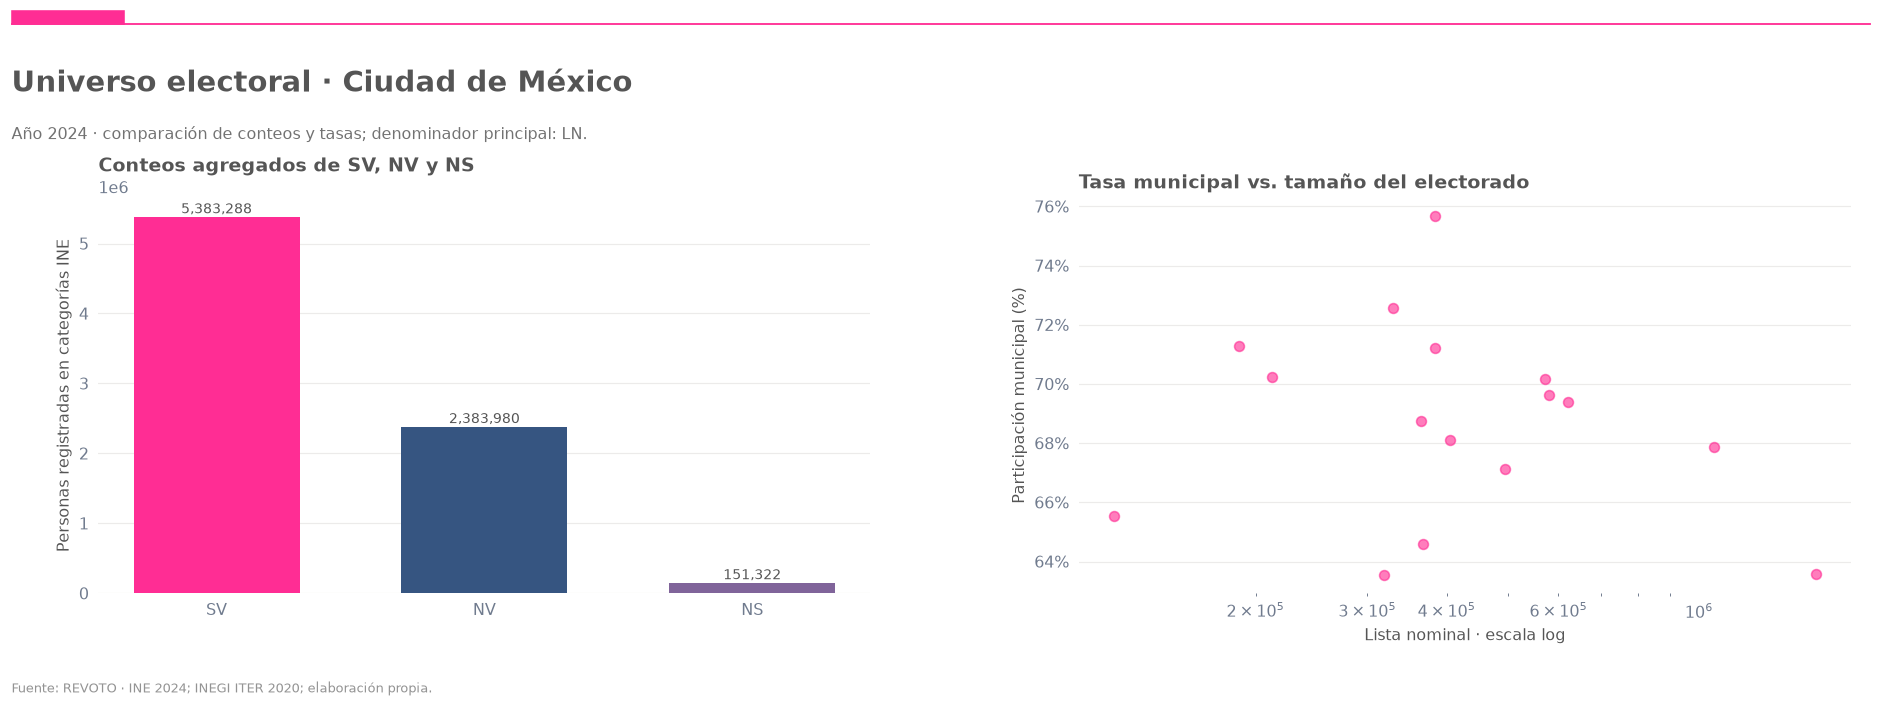

In [30]:
fig,axs=pagina(f'Universo electoral · {NOMBRE_ESTADO}',
    f'Año {ANIO_ELECTORAL} · comparación de conteos y tasas; denominador principal: {METRICA_PARTICIPACION}.')
a,b=axs
valores=electoral[['SV','NV','NS']].sum()
a.bar(valores.index,valores.values,color=[ACENTO,AZUL,MORADO],width=.62)
a.set_ylabel('Personas registradas en categorías INE')
a.set_title('Conteos agregados de SV, NV y NS',loc='left',weight='bold')
for i,v in enumerate(valores.values): a.text(i,v,f'{v:,.0f}',ha='center',va='bottom',fontsize=9)
b.scatter(electoral['LN'],electoral['tasa']*100,color=ACENTO,alpha=.62,s=38)
b.set_xscale('log');b.set_ylabel('Participación municipal (%)');b.set_xlabel('Lista nominal · escala log')
b.set_title('Tasa municipal vs. tamaño del electorado',loc='left',weight='bold')
marca_pct(b)
cerrar(fig,'01_universo_electoral')

## 2 · Correspondencia INE–INEGI (sin *fanout*)

El repo contiene equivalencias revisadas por `(EDOCVE, MPIOCVE, AELEC, censo_ref)`. Usamos `full_context` para localizar la clave INEGI original, generalmente de **nueve dígitos terminada en `0000`** para un total municipal. La transformamos en la clave **municipal de cinco dígitos**; **no** recortamos claves de localidades regulares. Si no existe `full_context`, buscamos el mapping manual aprobado. No se unen geográficamente los datos por el nombre del municipio.

In [31]:
def normalizar_cvegeo_municipal(s):
    bruto=s.astype('string').str.strip().str.replace(r'\.0$','',regex=True)
    # CSV numérico sin ceros iniciales: 010010000 -> 10010000; 01001 -> 1001.
    corto=bruto.str.fullmatch(r'\d{8}').fillna(False)
    bruto.loc[corto]='0'+bruto.loc[corto]
    corto5=bruto.str.fullmatch(r'\d{4}').fillna(False)
    bruto.loc[corto5]='0'+bruto.loc[corto5]
    ok5=bruto.str.fullmatch(r'\d{5}').fillna(False)
    ok9=bruto.str.fullmatch(r'\d{5}0000').fillna(False)
    out=pd.Series(pd.NA,index=s.index,dtype='string')
    out.loc[ok5]=bruto.loc[ok5]
    out.loc[ok9]=bruto.loc[ok9].str[:5]
    return out

RUTA_FULL=RAIZ/'data/processed/full_context'/f'edo={EDO}'/f'anio={ANIO_ELECTORAL}'/'municipios.parquet'
RUTA_MAPPING=RAIZ/'data/mappings/inegi_ine.csv'
mapa_llaves=pd.DataFrame(columns=['AELEC','EDOCVE','MPIOCVE','cvegeo_municipal','fuente_join'])

if RUTA_FULL.is_file():
    full=con.execute(f"""SELECT * FROM {lectura(RUTA_FULL)}
                   WHERE AELEC=? AND EDOCVE=?""",[ANIO_ELECTORAL,CLAVE_ESTADO]).fetchdf()
    if 'cvegeo_municipal_inegi' in full.columns:
        full['cvegeo_municipal']=normalizar_cvegeo_municipal(full['cvegeo_municipal_inegi'])
        if 'censo_ref' in full.columns:
            full=full.loc[pd.to_numeric(full.censo_ref,errors='coerce').eq(ANIO_CENSO)].copy()
        full=full.dropna(subset=['cvegeo_municipal'])
        mapa_llaves=full[['AELEC','EDOCVE','MPIOCVE','cvegeo_municipal']].copy()
        mapa_llaves['fuente_join']='full_context'

if RUTA_MAPPING.is_file():
    mp=pd.read_csv(RUTA_MAPPING,dtype='string',encoding='utf-8-sig')
    requerido={'anio_eleccion','censo_ref','cve_ent_ine','cve_mpio_ine','cvegeo_municipal_inegi'}
    if requerido.issubset(mp.columns):
        if 'status_match' in mp:
            mp=mp.loc[mp['status_match'].str.lower().eq('validado')].copy()
        mp=mp.loc[
            pd.to_numeric(mp['anio_eleccion'],errors='coerce').eq(ANIO_ELECTORAL)&
            pd.to_numeric(mp['censo_ref'],errors='coerce').eq(ANIO_CENSO)&
            pd.to_numeric(mp['cve_ent_ine'],errors='coerce').eq(CLAVE_ESTADO)
        ].copy()
        mp['cvegeo_municipal']=normalizar_cvegeo_municipal(mp['cvegeo_municipal_inegi'])
        mp=mp.dropna(subset=['cvegeo_municipal'])
        mp['AELEC']=ANIO_ELECTORAL;mp['EDOCVE']=CLAVE_ESTADO
        mp['MPIOCVE']=pd.to_numeric(mp['cve_mpio_ine'],errors='coerce')
        mp=mp[['AELEC','EDOCVE','MPIOCVE','cvegeo_municipal']].copy()
        mp['fuente_join']='mapping_validado'
        # No ignorar discrepancias entre el mapping aprobado y full_context.
        ya=mapa_llaves.merge(mp,on=['AELEC','EDOCVE','MPIOCVE'],how='inner',suffixes=('_full','_map'))
        bad=ya.loc[ya.cvegeo_municipal_full.ne(ya.cvegeo_municipal_map)]
        if not bad.empty: raise ValueError(f'{len(bad)} discrepancias mapping ↔ full_context')
        mp=mp[~mp.MPIOCVE.isin(mapa_llaves.MPIOCVE)]
        mapa_llaves=pd.concat([mapa_llaves,mp],ignore_index=True)

if not len(mapa_llaves) and PERMITIR_JOIN_CVEGEO_DIRECTO:
    mapa_llaves=electoral[['AELEC','EDOCVE','MPIOCVE']].copy()
    mapa_llaves['cvegeo_municipal']=electoral['cvegeo_ine']
    mapa_llaves['fuente_join']='directo_no_verificado'
    nota('Correspondencia directa habilitada: comprobar equivalencia de códigos por fuente y entidad.')

if mapa_llaves.empty:
    raise RuntimeError('Sin correspondencia INE–INEGI verificada. Ejecuta build-full-context o revisa mapping_inegi_ine.csv. No se inventó el join.')
if mapa_llaves.duplicated(['AELEC','EDOCVE','MPIOCVE']).any():
    raise ValueError('Correspondencia INE→INEGI no es 1:1')
if mapa_llaves.cvegeo_municipal.duplicated().any():
    raise ValueError('Dos municipios INE apuntan a un mismo municipio INEGI')
mapa_llaves['MPIOCVE']=pd.to_numeric(mapa_llaves.MPIOCVE,errors='coerce')
if mapa_llaves.cvegeo_municipal.str[:2].ne(EDO).any():
    raise ValueError('Las claves INEGI no corresponden al estado seleccionado')
print(f'Llaves revisadas: {len(mapa_llaves)}; por origen: {mapa_llaves.fuente_join.value_counts().to_dict()}')
mostrar(mapa_llaves)

Llaves revisadas: 16; por origen: {'full_context': 16}


,AELEC,EDOCVE,MPIOCVE,cvegeo_municipal,fuente_join
0,2024,9,6,09006,full_context
1,2024,9,8,09008,full_context
2,2024,9,9,09009,full_context
3,2024,9,10,09010,full_context
4,2024,9,12,09012,full_context
5,2024,9,3,09003,full_context
6,2024,9,15,09015,full_context
7,2024,9,4,09004,full_context
8,2024,9,13,09013,full_context
9,2024,9,7,09007,full_context


## 3 · INEGI ITER: totales municipales, variables y denominadores

**No sumar localidades** encima de totales municipales: eso duplicaría la población. El archivo staging tiene `cvegeo` de nueve dígitos y `record_level` que identifica el total municipal. Los indicadores `VPH_*` son **viviendas** y necesitan denominadores de viviendas; `P*` son **personas** y requieren denominadores poblacionales coherentes. Para el acceso a electricidad se puede derivar `1 − VPH_S_ELEC / viviendas habitadas` cuando esa definición está documentada.

In [32]:
RUTA_ITER=RAIZ/'data/staging/inegi'/f'censo={ANIO_CENSO}'/'iter.parquet'
if not RUTA_ITER.is_file():
    raise FileNotFoundError(f'ITER normalizado no encontrado: {RUTA_ITER}. Ejecuta build-inegi --censo {ANIO_CENSO}')
cols_iter={x[0] for x in con.execute(f'DESCRIBE SELECT * FROM {lectura(RUTA_ITER)}').fetchall()}
if not {'cvegeo','record_level','ENTIDAD'}.issubset(cols_iter):
    raise ValueError('Staging ITER sin columnas cvegeo / record_level / ENTIDAD')
VARIABLES_ITER=['POBTOT','P_15YMAS','P15YM_AN','GRAPROES',
                'VPH_INTER','VPH_CEL','VPH_S_ELEC','VPH_C_ELEC',
                'VIVPAR_HAB','TVIVPARHAB','P3YM_HLI','P_3YMAS','PHOG_IND','POB_AFRO']
consulta=', '.join(f'{ident(v)} AS {ident(v)}' if v in cols_iter
                  else f'NULL::DOUBLE AS {ident(v)}' for v in VARIABLES_ITER)
iter_mun=con.execute(f"""SELECT cvegeo, NOM_MUN, {consulta}
  FROM {lectura(RUTA_ITER)} WHERE record_level='total_municipal'
  AND TRY_CAST(ENTIDAD AS INTEGER)=?""",[CLAVE_ESTADO]).fetchdf()
iter_mun['cvegeo_municipal']=normalizar_cvegeo_municipal(iter_mun['cvegeo'])
if iter_mun.cvegeo_municipal.isna().any():
    raise ValueError('CVEGEO municipal inválida en total_municipal del ITER')
if iter_mun.cvegeo_municipal.duplicated().any():
    raise ValueError('Total municipal ITER duplicado: revisar censo/record_level')
print(f'Totales municipales ITER {ANIO_CENSO}: {len(iter_mun)}')

Totales municipales ITER 2020: 16


### 3.1 · Recuperación opcional de denominadores desde el CSV ITER original

La selección del staging de REVOTO no incluye siempre `VIVPAR_HAB`/`TVIVPARHAB` ni `P_3YMAS`. Si existen en el CSV original, se cargan **exclusivamente para totales municipales** de la entidad. Si no existen, la proporción afectada se deja nula; jamás se usa `POBTOT` como denominador de viviendas. Se preserva la distinción entre `*` (supresión) y cero.

In [33]:
RUTA_RAW = RAIZ/'data/raw/inegi'/str(ANIO_CENSO)
raw_csv=sorted(RUTA_RAW.glob('*.csv')) if RUTA_RAW.exists() else []
RAW_EXTRA=['VIVPAR_HAB','TVIVPARHAB','P_3YMAS','VPH_C_ELEC']
recuperadas=[]
if USAR_CSV_ITER_PARA_DENOMINADORES and len(raw_csv)==1:
    src=lit(raw_csv[0].as_posix())
    raw_sql=f'read_csv_auto({src}, all_varchar=true, header=true)'
    try:
        cols_raw={x[0].upper():x[0] for x in con.execute(f'DESCRIBE SELECT * FROM {raw_sql}').fetchall()}
        if {'ENTIDAD','MUN','LOC'}.issubset(cols_raw):
            faltantes=[c for c in RAW_EXTRA if c not in cols_iter and c in cols_raw]
            if faltantes:
                selects=', '.join("TRY_CAST(NULLIF(TRIM({}), '*') AS DOUBLE) AS {}".format(ident(cols_raw[c]),ident(c)) for c in faltantes)
                # El SQL obliga a entidad y LOC=0000; ninguna localidad regular entra.
                raw_extra=con.execute(f"""SELECT
                      LPAD(TRIM({ident(cols_raw['ENTIDAD'])}),2,'0') ||
                      LPAD(TRIM({ident(cols_raw['MUN'])}),3,'0') AS cvegeo_municipal,
                      {selects}
                    FROM {raw_sql}
                    WHERE TRY_CAST({ident(cols_raw['ENTIDAD'])} AS INTEGER)=?
                      AND TRY_CAST({ident(cols_raw['MUN'])} AS INTEGER)>0
                      AND TRY_CAST({ident(cols_raw['LOC'])} AS INTEGER)=0""",
                    [CLAVE_ESTADO]).fetchdf()
                if raw_extra.cvegeo_municipal.duplicated().any():
                    raise ValueError('Totales municipales duplicados en CSV ITER original')
                iter_mun=iter_mun.merge(raw_extra,on='cvegeo_municipal',how='left',validate='one_to_one',suffixes=('','_raw'))
                for col in faltantes:
                    if col+'_raw' in iter_mun:
                        iter_mun[col]=iter_mun[col].combine_first(iter_mun[col+'_raw'])
                        iter_mun=iter_mun.drop(columns=[col+'_raw'])
                recuperadas=faltantes
        else:
            nota('El CSV original no contiene ENTIDAD/MUN/LOC. No se cargaron denominadores.')
    except Exception as err:
        print('CSV original no procesado:',type(err).__name__,str(err)[:260])
        nota('No se imputan denominadores. Si faltan indicadores, verificar delimitador, codificación y esquema del ITER original.')
elif USAR_CSV_ITER_PARA_DENOMINADORES:
    print(f'Se esperaba exactamente un CSV ITER en {RUTA_RAW}; encontrados {len(raw_csv)}.')
print('Denominadores adicionales recuperados del CSV:',recuperadas or 'ninguno')
mostrar(iter_mun[['cvegeo_municipal','NOM_MUN',*VARIABLES_ITER]].head(8))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Denominadores adicionales recuperados del CSV: ['VIVPAR_HAB', 'TVIVPARHAB', 'P_3YMAS', 'VPH_C_ELEC']


,cvegeo_municipal,NOM_MUN,POBTOT,P_15YMAS,P15YM_AN,GRAPROES,VPH_INTER,VPH_CEL,VPH_S_ELEC,VPH_C_ELEC,VIVPAR_HAB,TVIVPARHAB,P3YM_HLI,P_3YMAS,PHOG_IND,POB_AFRO
0,09002,Azcapotzalco,432205,361474,3675,11.91,105899,123961,38,133798.0,130090.0,134168.0,3208,420056.0,7261,8864
1,09003,Coyoacán,614447,522992,5765,12.51,157908,179280,61,191126.0,182787.0,191517.0,7728,599528.0,15349,11120
2,09004,Cuajimalpa de Morelos,217686,172263,2575,11.44,46389,56543,31,60308.0,47436.0,60436.0,2046,209540.0,4022,3053
3,09005,Gustavo A. Madero,1173351,960772,14594,11.11,246278,306796,160,339504.0,332156.0,340155.0,14196,1137856.0,33035,21697
4,09006,Iztacalco,404695,335205,3880,11.52,91039,108707,52,117396.0,112687.0,117720.0,4412,392990.0,10060,6941
5,09007,Iztapalapa,1835486,1468256,26774,10.42,349103,455216,300,503261.0,489238.0,504365.0,28716,1777184.0,73036,33313
6,09008,La Magdalena Contreras,247622,200201,3733,10.84,50653,62286,76,67911.0,63122.0,68089.0,2890,240358.0,6796,5459
7,09009,Milpa Alta,152685,116360,3219,9.95,19798,33845,151,38879.0,37668.0,39100.0,4891,146847.0,13002,2231


## 4 · Dataset analítico unido y calidad de las correspondencias

La unión es siempre `municipio INE → mapping verificado → total_municipal INEGI` con `validate='one_to_one'`. Los nombres son informativos, nunca una llave de unión. No se fuerza una coincidencia de datos faltantes.

In [34]:
base=electoral.merge(mapa_llaves,on=['AELEC','EDOCVE','MPIOCVE'],how='left',validate='one_to_one',indicator='match_mapping')
base=base.merge(iter_mun.drop(columns=['cvegeo']),on='cvegeo_municipal',how='left',validate='one_to_one',indicator='match_iter')
base['cvegeo_municipal']=base.cvegeo_municipal.astype('string')
for col in VARIABLES_ITER:
    base[col]=pd.to_numeric(base[col],errors='coerce')
auditoria_join=pd.DataFrame([{
    'estado':NOMBRE_ESTADO,'eleccion':ANIO_ELECTORAL,'censo_ref':ANIO_CENSO,
    'municipios_electorales':len(electoral),'con_mapping':int(base.match_mapping.eq('both').sum()),
    'con_total_municipal_ITER':int(base.match_iter.eq('both').sum()),
    'con_POBTOT':int(base.POBTOT.notna().sum()),
    'sin_mapping':int(base.match_mapping.eq('left_only').sum()),
    'sin_ITER':int(base.match_iter.eq('left_only').sum()),
    'clave_invalida':int(base.cvegeo_municipal.isna().sum())
}])
mostrar(auditoria_join)
if auditoria_join.iloc[0]['con_total_municipal_ITER'] < len(electoral):
    nota('La cobertura del cruce es parcial. Las correlaciones se calculan solamente con municipios emparejados y el n real se muestra por variable.')
mostrar(base[['MPIOCVE','cvegeo_municipal','NOM_MUN','LN','SV','NV','NS','tasa','POBTOT']].head(12))

,estado,eleccion,censo_ref,municipios_electorales,con_mapping,con_total_municipal_ITER,con_POBTOT,sin_mapping,sin_ITER,clave_invalida
0,Ciudad de México,2024,2020,16,16,16,16,0,0,0


,MPIOCVE,cvegeo_municipal,NOM_MUN,LN,SV,NV,NS,tasa,POBTOT
0,2,09002,Azcapotzalco,384017,273485,106454,4078,0.712169,432205
1,3,09003,Coyoacán,571993,401449,148552,21992,0.701843,614447
2,4,09004,Cuajimalpa de Morelos,188128,134127,50416,3585,0.712956,217686
3,5,09005,Gustavo A. Madero,1055917,716527,317350,22040,0.678583,1173351
4,6,09006,Iztacalco,364028,250210,110369,3449,0.687337,404695
5,7,09007,Iztapalapa,1524929,969535,501425,53969,0.635790,1835486
6,8,09008,La Magdalena Contreras,212549,149285,61675,1589,0.702356,247622
7,9,09009,Milpa Alta,119674,78416,40536,722,0.655247,152685
8,10,09010,Álvaro Obregón,620970,430960,180535,9475,0.694011,759137
9,11,09011,Tláhuac,318687,202477,113564,2646,0.635348,392313


### 4.1 · Contrato de indicadores y denominadores comprobables

Cada *porcentaje* exige un numerador y denominador válidos dentro de la **misma unidad de análisis**. No se divide `VPH_INTER` (viviendas) entre `POBTOT` (personas). Las variables `P3YM_HLI` y `PHOG_IND` miden cosas distintas, al igual que población indígena y afromexicana. El objetivo es un análisis **municipal ecológico**, no la atribución de comportamientos a sus residentes.

In [35]:
def pct(num,den,*,invertir=False):
    n=pd.to_numeric(num,errors='coerce'); d=pd.to_numeric(den,errors='coerce')
    r=safe_div(n,d)
    r=r.where(n.ge(0)&d.ge(n)&d.gt(0)&r.between(0,1))
    return 100*(1-r if invertir else r)

def primero_disponible(df,candidatos):
    # Un denominador debe tener valores válidos, no solo existir como columna NULL.
    return next((c for c in candidatos if c in df and df[c].notna().any()),None)

DEN_VIV=primero_disponible(base,['VIVPAR_HAB','TVIVPARHAB'])
DEN_IND=primero_disponible(base,['P_3YMAS'])
INDICADORES={}

def agregar_indicador(id_,dominio,titulo,unidad,fuente,descripcion,serie,orientacion='mayor'):
    base[id_]=pd.to_numeric(serie,errors='coerce')
    base[id_]=base[id_].replace([np.inf,-np.inf],np.nan)
    if unidad=='%': base[id_]=base[id_].where(base[id_].between(0,100))
    INDICADORES[id_]={'dominio':dominio,'titulo':titulo,'unidad':unidad,
        'fuente':fuente,'descripcion':descripcion,'orientacion':orientacion}

if DEN_VIV:
    agregar_indicador('acceso_electricidad','electricidad','Viviendas con electricidad (derivado)','%',
        'VPH_S_ELEC / '+DEN_VIV,'100 − porcentaje de viviendas sin electricidad',
        pct(base.VPH_S_ELEC,base[DEN_VIV],invertir=True))
    agregar_indicador('internet_viviendas','internet','Viviendas con internet','%',
        'VPH_INTER / '+DEN_VIV,'Viviendas particulares habitadas con internet',pct(base.VPH_INTER,base[DEN_VIV]))
    agregar_indicador('celular_viviendas','celulares','Viviendas con celular','%',
        'VPH_CEL / '+DEN_VIV,'Viviendas particulares habitadas que disponen de celular',pct(base.VPH_CEL,base[DEN_VIV]))
else:
    for id_,dom,ti,desc in [
        ('acceso_electricidad','electricidad','Viviendas con electricidad (derivado)','VPH_S_ELEC'),
        ('internet_viviendas','internet','Viviendas con internet','VPH_INTER'),
        ('celular_viviendas','celulares','Viviendas con celular','VPH_CEL')]:
        agregar_indicador(id_,dom,ti,'%',f'{desc} / denominador viviendas no disponible',
            'Sin denominador verificado, no se calcula una tasa',
            pd.Series(np.nan,index=base.index))

agregar_indicador('escolaridad','educacion','Grado promedio de escolaridad','años',
    'GRAPROES','Años promedio de escolaridad, población objetivo definida por INEGI',base.GRAPROES.where(base.GRAPROES.between(0,30)))
agregar_indicador('sin_analfabetismo_15','educacion','Población 15+ no analfabeta (derivado)','%',
    '1 − P15YM_AN / P_15YMAS', 'Complemento de población de 15 años y más analfabeta',
    pct(base.P15YM_AN,base.P_15YMAS,invertir=True))

if DEN_IND:
    agregar_indicador('habla_lengua_indigena','indigena','Población 3+ hablante de lengua indígena','%',
        'P3YM_HLI / P_3YMAS', 'Porcentaje entre población de 3 años y más',
        pct(base.P3YM_HLI,base[DEN_IND]))
else:
    agregar_indicador('habla_lengua_indigena','indigena','Población 3+ hablante de lengua indígena','%',
        'P3YM_HLI / P_3YMAS (no disponible)', 'Sin denominador; no se estima este porcentaje',
        pd.Series(np.nan,index=base.index))
agregar_indicador('hogares_indigenas','indigena','Población en hogares indígenas','%',
    'PHOG_IND / POBTOT','Proporción de la población total en hogares indígenas (NO equivale a hablantes)',
    pct(base.PHOG_IND,base.POBTOT))
agregar_indicador('afromexicana','afro','Población afromexicana o afrodescendiente','%',
    'POB_AFRO / POBTOT','Población que se reconoce afromexicana/afrodescendiente sobre total censal',
    pct(base.POB_AFRO,base.POBTOT))

DOMINIOS=[
    ('electricidad','Acceso a electricidad','acceso_electricidad'),
    ('educacion','Educación','escolaridad'),
    ('internet','Acceso a internet','internet_viviendas'),
    ('celulares','Disponibilidad de celular','celular_viviendas'),
    ('indigena','Población indígena: lengua y hogares','habla_lengua_indigena'),
    ('afro','Población afromexicana','afromexicana'),
]
CONTRATO=pd.DataFrame([
    {'variable':k,**d,'n_disponible':int(base[k].notna().sum()),
     'pct_municipios_disponible':round(100*base[k].notna().mean(),1)}
    for k,d in INDICADORES.items()
])
mostrar(CONTRATO,30)

,variable,dominio,titulo,unidad,fuente,descripcion,orientacion,n_disponible,pct_municipios_disponible
0,acceso_electricidad,electricidad,Viviendas con electricidad (derivado),%,VPH_S_ELEC / VIVPAR_HAB,100 − porcentaje de viviendas sin electricidad,mayor,16,100.0
1,internet_viviendas,internet,Viviendas con internet,%,VPH_INTER / VIVPAR_HAB,Viviendas particulares habitadas con internet,mayor,14,87.5
2,celular_viviendas,celulares,Viviendas con celular,%,VPH_CEL / VIVPAR_HAB,Viviendas particulares habitadas que disponen ...,mayor,11,68.8
3,escolaridad,educacion,Grado promedio de escolaridad,años,GRAPROES,"Años promedio de escolaridad, población objeti...",mayor,16,100.0
4,sin_analfabetismo_15,educacion,Población 15+ no analfabeta (derivado),%,1 − P15YM_AN / P_15YMAS,Complemento de población de 15 años y más anal...,mayor,16,100.0
5,habla_lengua_indigena,indigena,Población 3+ hablante de lengua indígena,%,P3YM_HLI / P_3YMAS,Porcentaje entre población de 3 años y más,mayor,16,100.0
6,hogares_indigenas,indigena,Población en hogares indígenas,%,PHOG_IND / POBTOT,Proporción de la población total en hogares in...,mayor,16,100.0
7,afromexicana,afro,Población afromexicana o afrodescendiente,%,POB_AFRO / POBTOT,Población que se reconoce afromexicana/afrodes...,mayor,16,100.0


### 4.2 · Tabla de calidad y disponibilidad por dimensión

La ausencia de un denominador o los valores suprimidos de ITER no son ceros. Cuando falten datos una dimensión tendrá un aviso explícito y no una nube de puntos vacía.

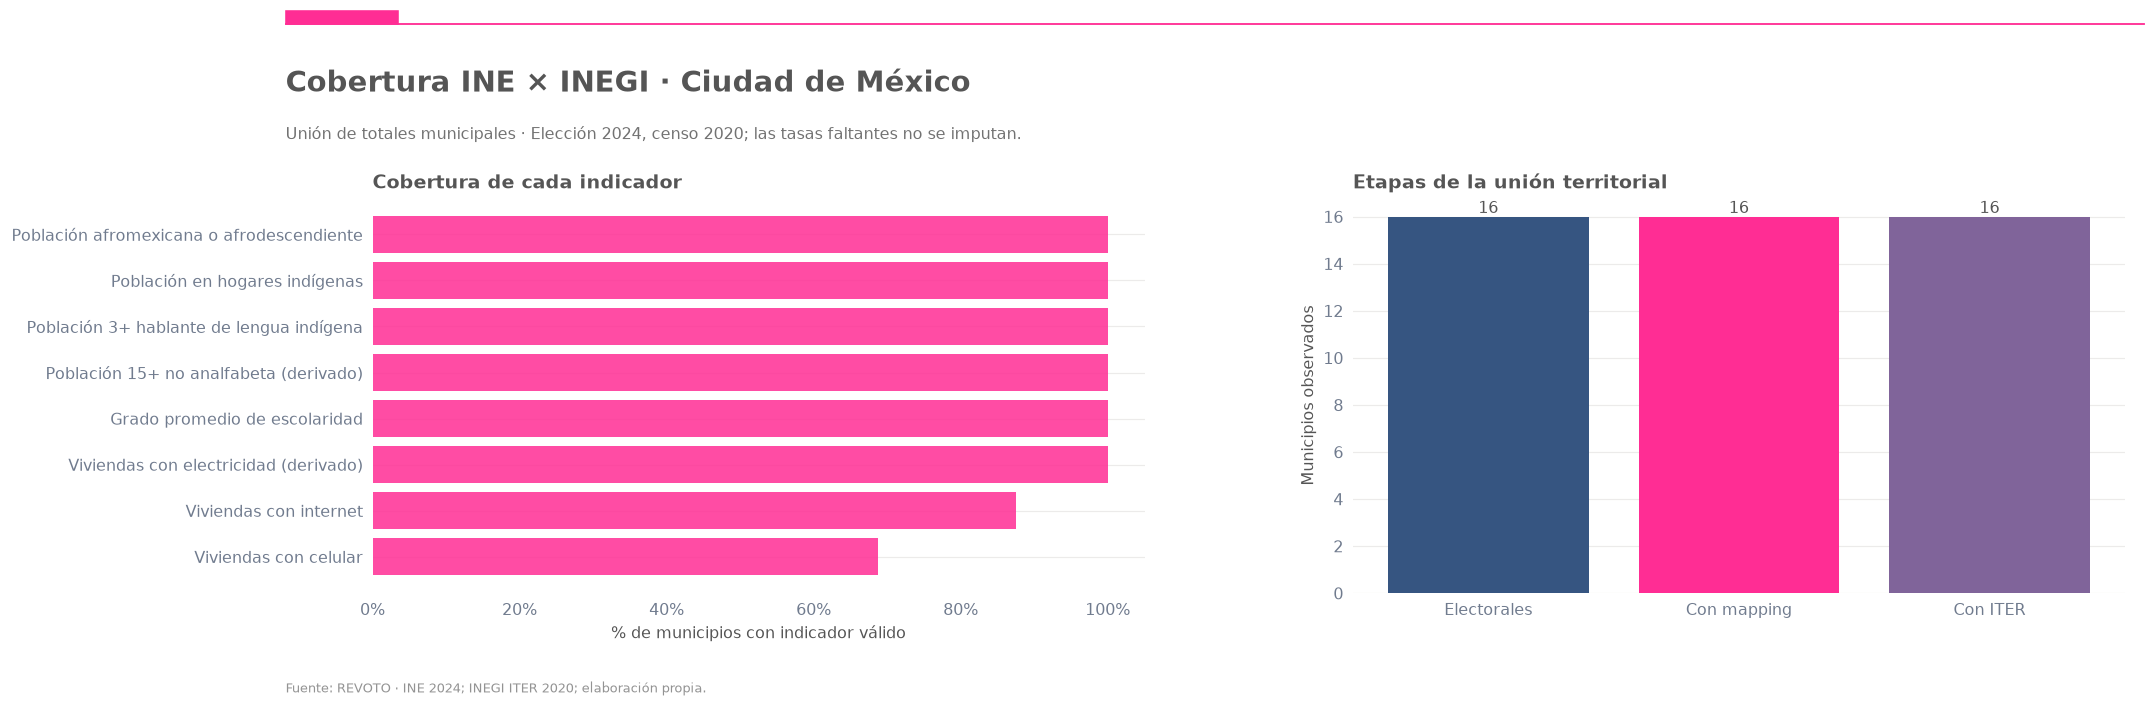

In [36]:
fig,axs=pagina(f'Cobertura INE × INEGI · {NOMBRE_ESTADO}',
   f'Unión de totales municipales · Elección {ANIO_ELECTORAL}, censo {ANIO_CENSO}; las tasas faltantes no se imputan.')
a,b=axs
cols=CONTRATO.sort_values('pct_municipios_disponible')
a.barh(cols.titulo,cols.pct_municipios_disponible,color=ACENTO,alpha=.85)
a.set_xlim(0,105);a.set_xlabel('% de municipios con indicador válido')
a.set_title('Cobertura de cada indicador',loc='left',weight='bold')
marca_pct(a,'x')
cont=pd.Series({'Electorales':len(electoral),
    'Con mapping':int(base.match_mapping.eq('both').sum()),
    'Con ITER':int(base.match_iter.eq('both').sum())})
b.bar(cont.index,cont.values,color=[AZUL,ACENTO,MORADO])
b.set_title('Etapas de la unión territorial',loc='left',weight='bold')
b.set_ylabel('Municipios observados')
for i,v in enumerate(cont.values): b.text(i,v,str(v),ha='center',va='bottom')
cerrar(fig,'02_cobertura_y_join')

## 5 · Motor analítico común: relaciones y distribuciones por cuartiles

**Gráfica izquierda:** cada punto es un municipio; coeficiente de Spearman, tamaño muestral real y coeficiente de asociación cuando proceda. **Gráfica derecha:** distribución de las tasas por cuartiles del indicador: diagramas de caja con puntos individuales. Los cuartiles agrupan municipios, no personas. No se utilizan medias simples de porcentajes para calcular una tasa agregada.

Se repite el mismo contrato para las seis dimensiones. Un ρ positivo significa que municipios con más del indicador **tienden** a presentar tasas mayores, no que las personas que poseen esa característica votan más.

In [37]:
def dataset_indicador(nombre,umbral=0):
    if nombre not in INDICADORES: raise KeyError(nombre)
    cols=['cvegeo_municipal','NOM_MUN','LN','SV','NV','NS','denominador','tasa',
          'POBTOT',nombre]
    d=base[cols].copy()
    d=d.replace([np.inf,-np.inf],np.nan)
    d=d.loc[d.LN.ge(umbral)&d.tasa.between(0,1)&d[nombre].notna()].copy()
    return d

def correlacion(d,x):
    if len(d)<N_MIN_CORRELACION or d[x].nunique()<3 or d.tasa.nunique()<3:
        return np.nan,np.nan,np.nan
    rho=float(d[x].corr(d.tasa,method='spearman'))
    if not np.isfinite(rho): return np.nan,np.nan,np.nan
    xv=d[x].to_numpy(dtype=float)
    yv=d.tasa.to_numpy(dtype=float)
    rng=np.random.default_rng(20261012)
    boot=[]
    for _ in range(N_BOOTSTRAP):
        idx=rng.integers(0,len(d),len(d))
        sample_x=pd.Series(xv[idx]);sample_y=pd.Series(yv[idx])
        if sample_x.nunique()>1 and sample_y.nunique()>1:
            b=sample_x.corr(sample_y,method='spearman')
            if np.isfinite(b): boot.append(float(b))
    ci=np.quantile(boot,[.025,.975]) if len(boot)>=30 else [np.nan,np.nan]
    return rho,ci[0],ci[1]

def asignar_cuartiles(d,nombre):
    r=d.copy()
    if len(r)<8 or r[nombre].nunique()<4:
        r['cuartil']=pd.Series(pd.NA,index=r.index,dtype='object')
        return r
    # Rango = partición única por municipio; empates altos no implican un valor umbral único.
    ranks=r[nombre].rank(method='first')
    r['cuartil']=pd.qcut(ranks,4,labels=['Q1 · menor','Q2','Q3','Q4 · mayor']).astype('string')
    return r

def ficha_indicador(nombre):
    d=dataset_indicador(nombre)
    rho,lo,hi=correlacion(d,nombre)
    return {'indicador':nombre,'dominio':INDICADORES[nombre]['dominio'],
        'descripcion':INDICADORES[nombre]['descripcion'],
        'fuente':INDICADORES[nombre]['fuente'],
        'n':len(d),'porcentaje_cobertura':round(100*len(d)/len(electoral),1),
        'rho_spearman':rho,'ci95_inf_boot':lo,'ci95_sup_boot':hi}

RESULTADOS=pd.DataFrame([ficha_indicador(k) for k in INDICADORES])
CUARTILES={}

def dibujar_dimension(dominio,nombre,principal,alternos=()):
    candidatos=[principal,*alternos]
    viable=next((k for k in candidatos if len(dataset_indicador(k))>=N_MIN_CORRELACION
                 and dataset_indicador(k)[k].nunique()>=4),None)
    if viable is None:
        nota(f'**{nombre}:** datos insuficientes para correlación y cuartiles válidos. '
             f'Variables intentadas: {candidatos}. Revisa `CONTRATO` y la disponibilidad de denominadores del ITER.')
        return
    m=INDICADORES[viable]
    d=asignar_cuartiles(dataset_indicador(viable),viable)
    rho,lo,hi=correlacion(d,viable)
    fig,axs=pagina(f'{nombre} × participación · {NOMBRE_ESTADO}',
        f'Elección {ANIO_ELECTORAL} · censo {ANIO_CENSO} · asociación municipal, no individual. '
        f'Indicador: {m["titulo"]}; n={len(d)}.',
        fuente=f'REVOTO · INE {ANIO_ELECTORAL} (SV, LN, NS); INEGI ITER {ANIO_CENSO} ({m["fuente"]}).')
    a,b=axs
    a.scatter(d[viable],d.tasa*100,color=ACENTO,s=40,alpha=.6,edgecolors='white',linewidths=.45)
    a.set_ylabel('Participación municipal (%)')
    a.set_xlabel(f'{m["titulo"]} ({m["unidad"]})')
    a.set_title('Asociación municipal y dispersión',loc='left',weight='bold',pad=18)
    a.text(.01,1.015,f'ρ Spearman = {rho:+.2f} | rango bootstrap 95% [{lo:+.2f}, {hi:+.2f}]',
         transform=a.transAxes,fontsize=9,color=GRIS2)
    marca_pct(a)
    orden=['Q1 · menor','Q2','Q3','Q4 · mayor']
    valores=[(d.loc[d.cuartil.eq(q),'tasa']*100).to_numpy() for q in orden]
    if all(len(x)>0 for x in valores):
        bp=b.boxplot(valores,positions=np.arange(1,5),widths=.52,patch_artist=True,
                     showfliers=False,medianprops={'color':ACENTO_OSCURO,'linewidth':2},
                     whiskerprops={'color':AZUL},capprops={'color':AZUL})
        for p in bp['boxes']: p.set(facecolor=CLARO,edgecolor=ACENTO,linewidth=1.1)
        rng=np.random.default_rng(21)
        for j,arr in enumerate(valores,1):
            b.scatter(j+rng.uniform(-.15,.15,len(arr)),arr,s=17,color=ACENTO,
                      alpha=.48,zorder=3)
        b.set_xticks(range(1,5),['Q1','Q2','Q3','Q4'])
        b.set_ylabel('Participación municipal (%)')
        b.set_xlabel('Cuartiles del indicador · municipio')
        b.set_title('Heterogeneidad dentro de cada cuartil',loc='left',weight='bold')
        marca_pct(b)
        b.text(.01,1.02,'Q1: menor valor  →  Q4: mayor valor',
               transform=b.transAxes,color=GRIS2,fontsize=9)
    else:
        b.set_axis_off();b.text(.5,.5,'Cuartiles no estimables',ha='center',va='center',transform=b.transAxes)
    cerrar(fig,f'05_{dominio}')
    filas=[]
    for q,sub in d.groupby('cuartil',dropna=True,observed=True):
        filas.append({'dimension':dominio,'indicador':viable,'cuartil':q,'n':len(sub),
           'participacion_mediana_pct':100*sub.tasa.median(),
           'participacion_ponderada_pct':100*sub.SV.sum()/sub.denominador.sum(),
           'indicador_mediana':sub[viable].median()})
    CUARTILES[dominio]=pd.DataFrame(filas)
    mostrar(CUARTILES[dominio],8)

### 5.1 · Electricidad

Acceso derivado como complemento de viviendas sin electricidad. Los indicadores de viviendas se comparan contra tasas del electorado municipal, no contra participación de usuarios.

Dos lecturas complementarias, sujetas a cobertura suficiente: **relación bivariada** y **dispersión por cuartiles municipales**. El reporte indica fuente, denominador y `n`.

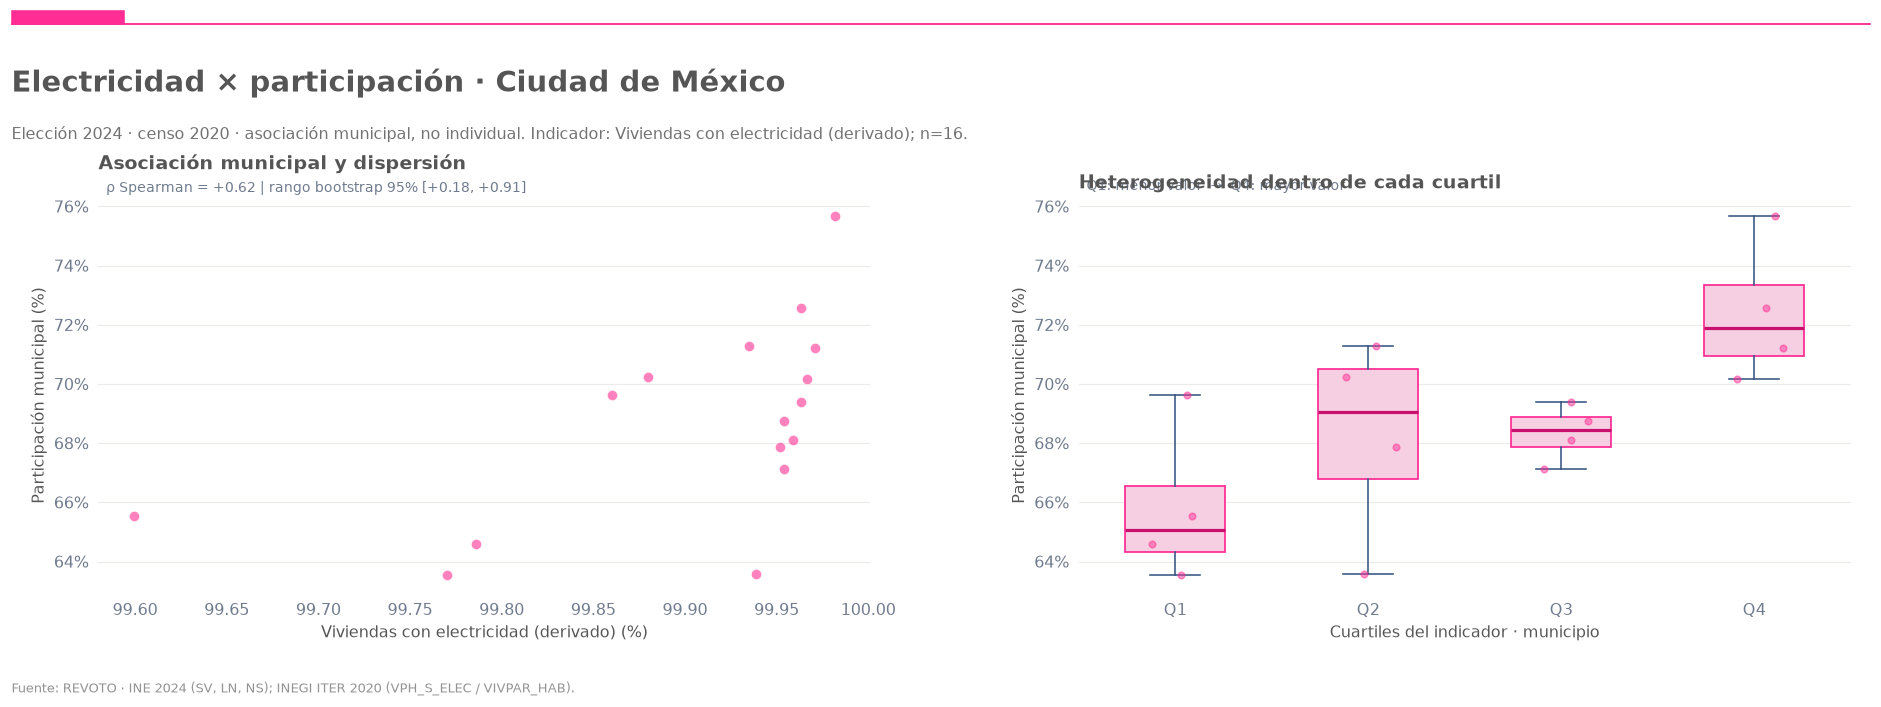

,dimension,indicador,cuartil,n,participacion_mediana_pct,participacion_ponderada_pct,indicador_mediana
0,electricidad,acceso_electricidad,Q1 · menor,4,65.060011,66.530543,99.777955
1,electricidad,acceso_electricidad,Q2,4,69.046919,66.055972,99.936664
2,electricidad,acceso_electricidad,Q3,4,68.427840,68.401387,99.956458
3,electricidad,acceso_electricidad,Q4 · mayor,4,71.895680,72.157564,99.968709


In [38]:
dibujar_dimension('electricidad', 'Electricidad', 'acceso_electricidad', ())

### 5.2 · Educación

El grado promedio de escolaridad es una medida continua en años, distinta de la proporción de adultos sin analfabetismo.

Dos lecturas complementarias, sujetas a cobertura suficiente: **relación bivariada** y **dispersión por cuartiles municipales**. El reporte indica fuente, denominador y `n`.

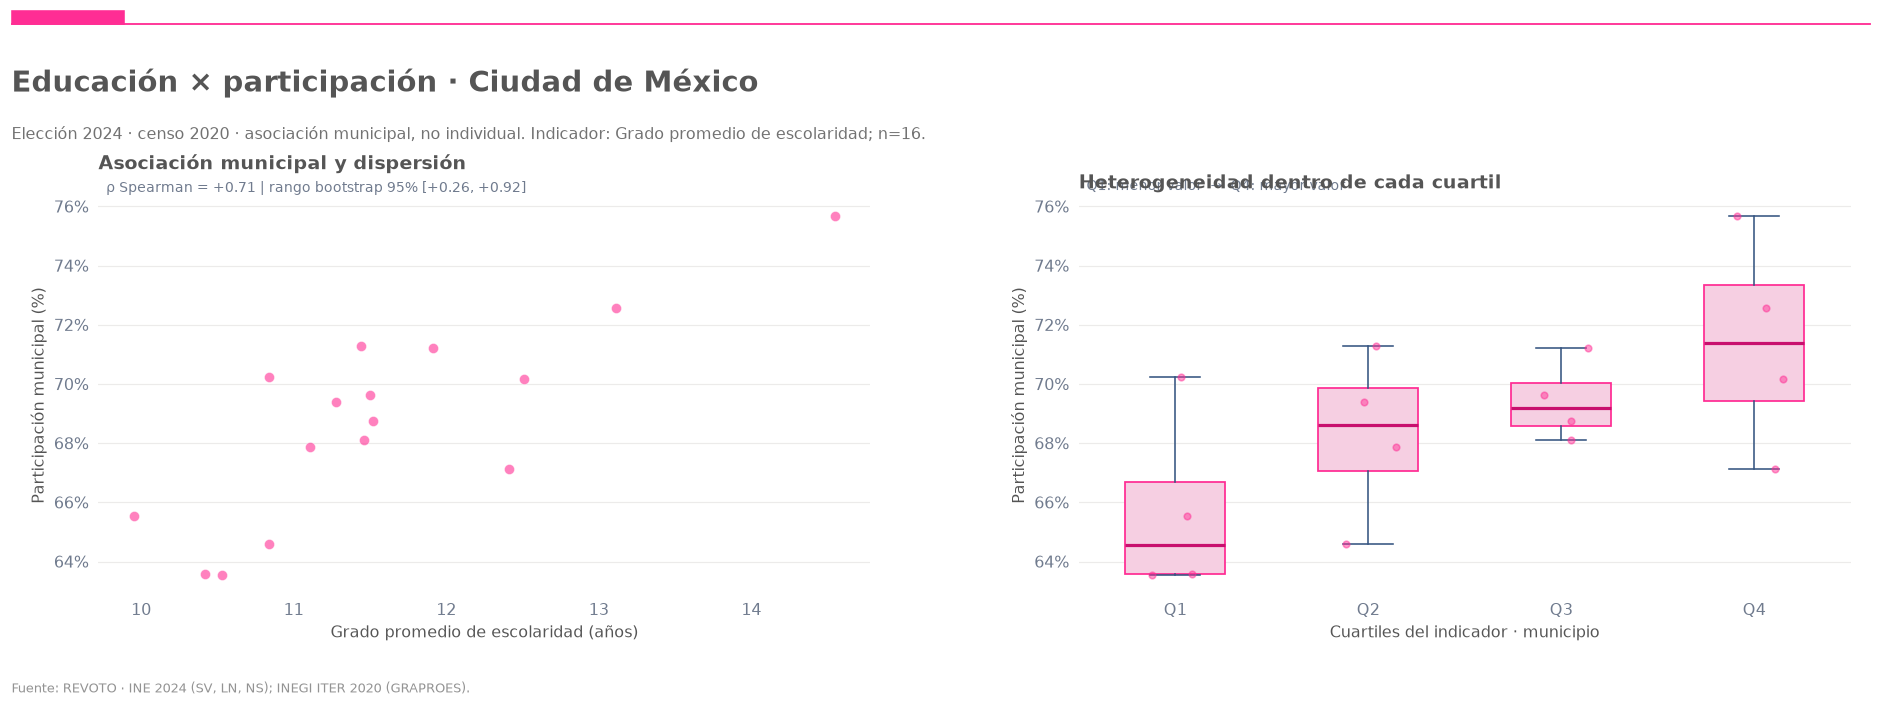

,dimension,indicador,cuartil,n,participacion_mediana_pct,participacion_ponderada_pct,indicador_mediana
0,educacion,escolaridad,Q1 · menor,4,64.551851,64.329806,10.475
1,educacion,escolaridad,Q2,4,68.629684,68.039676,11.195
2,educacion,escolaridad,Q3,4,69.175686,69.437011,11.510
3,educacion,escolaridad,Q4 · mayor,4,71.379356,70.964994,12.810


In [39]:
dibujar_dimension('educacion', 'Educación', 'escolaridad', ('sin_analfabetismo_15',))

### 5.3 · Internet

Porcentaje de viviendas particulares habitadas con acceso a internet; no equivale a porcentaje de electores con internet.

Dos lecturas complementarias, sujetas a cobertura suficiente: **relación bivariada** y **dispersión por cuartiles municipales**. El reporte indica fuente, denominador y `n`.

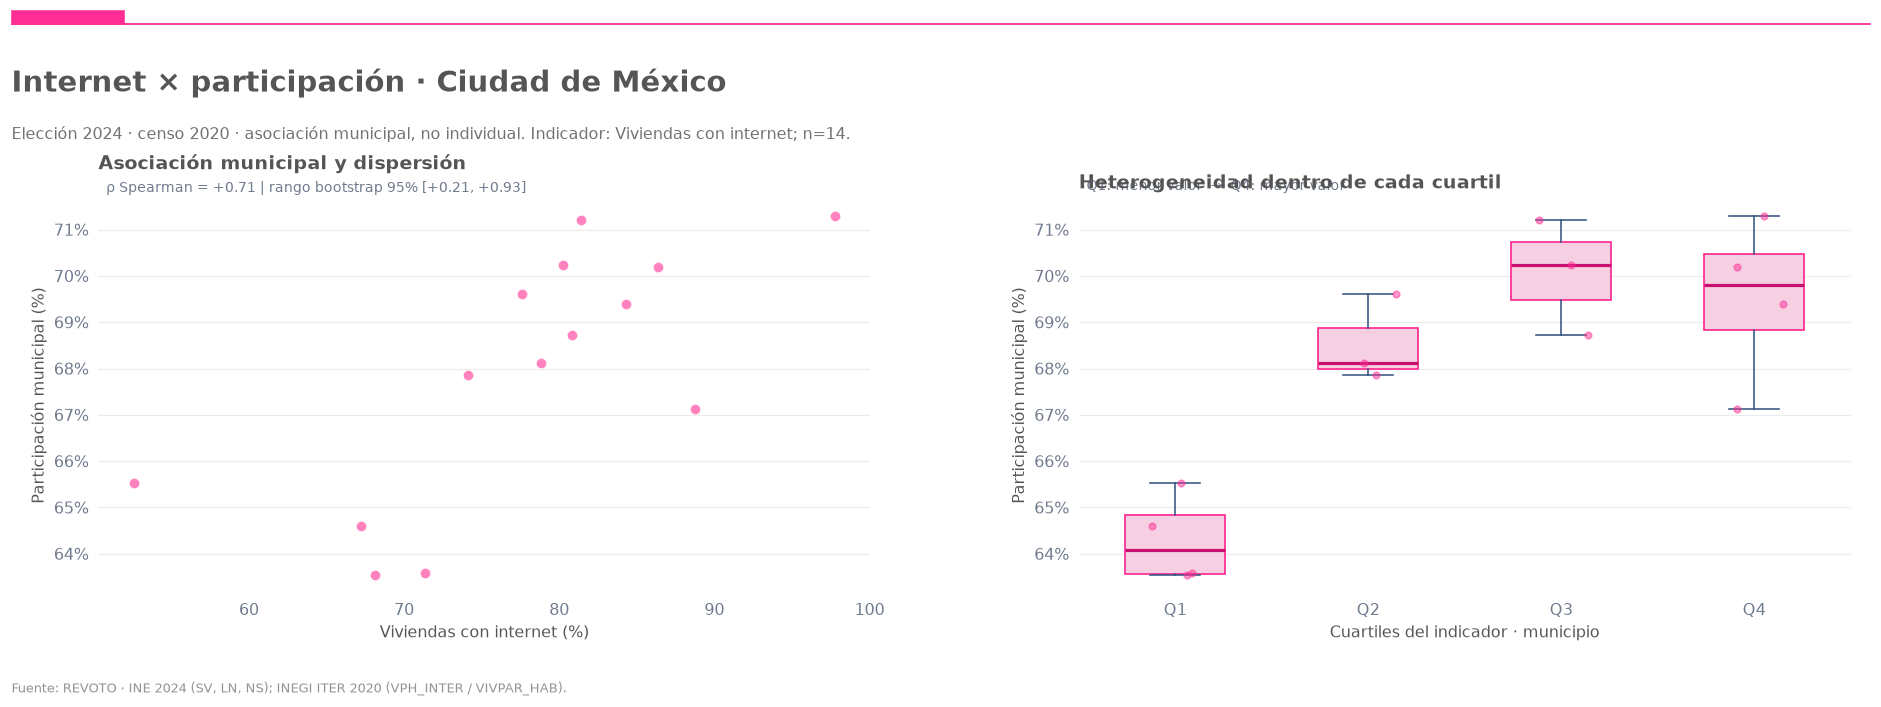

,dimension,indicador,cuartil,n,participacion_mediana_pct,participacion_ponderada_pct,indicador_mediana
0,internet,internet_viviendas,Q1 · menor,4,64.087186,63.833173,67.675057
1,internet,internet_viviendas,Q2,3,68.121957,68.409898,77.624994
2,internet,internet_viviendas,Q3,3,70.235569,70.058734,80.789266
3,internet,internet_viviendas,Q4 · mayor,4,69.792674,69.231606,87.554522


In [40]:
dibujar_dimension('internet', 'Internet', 'internet_viviendas', ())

### 5.4 · Celulares

Porcentaje de viviendas particulares habitadas con celular; no implica que cada persona registrada tenga teléfono.

Dos lecturas complementarias, sujetas a cobertura suficiente: **relación bivariada** y **dispersión por cuartiles municipales**. El reporte indica fuente, denominador y `n`.

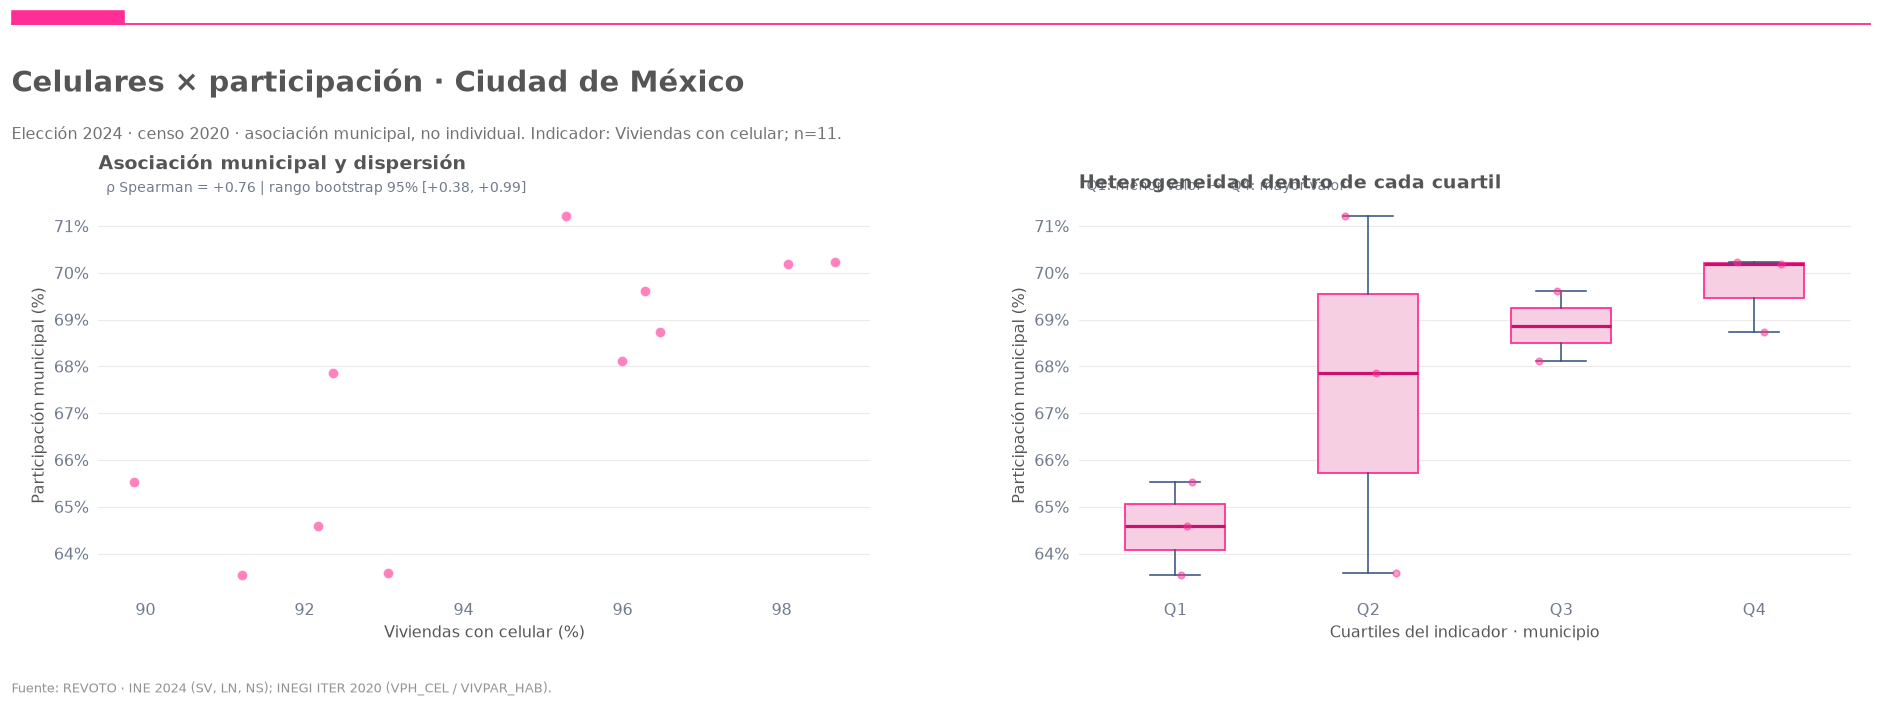

,dimension,indicador,cuartil,n,participacion_mediana_pct,participacion_ponderada_pct,indicador_mediana
0,celulares,celular_viviendas,Q1 · menor,3,64.595346,64.313992,91.209997
1,celulares,celular_viviendas,Q2,3,67.858269,66.092329,93.045920
2,celulares,celular_viviendas,Q3,2,68.869802,69.002262,96.133736
3,celulares,celular_viviendas,Q4 · mayor,3,70.184251,69.734017,98.081373


In [41]:
dibujar_dimension('celulares', 'Celulares', 'celular_viviendas', ())

### 5.5 · Población indígena

El indicador de lengua indígena entre población de 3+ tiene prioridad. Si falta, se visualiza población en hogares indígenas, expresamente etiquetada como concepto diferente. No se equiparan.

Dos lecturas complementarias, sujetas a cobertura suficiente: **relación bivariada** y **dispersión por cuartiles municipales**. El reporte indica fuente, denominador y `n`.

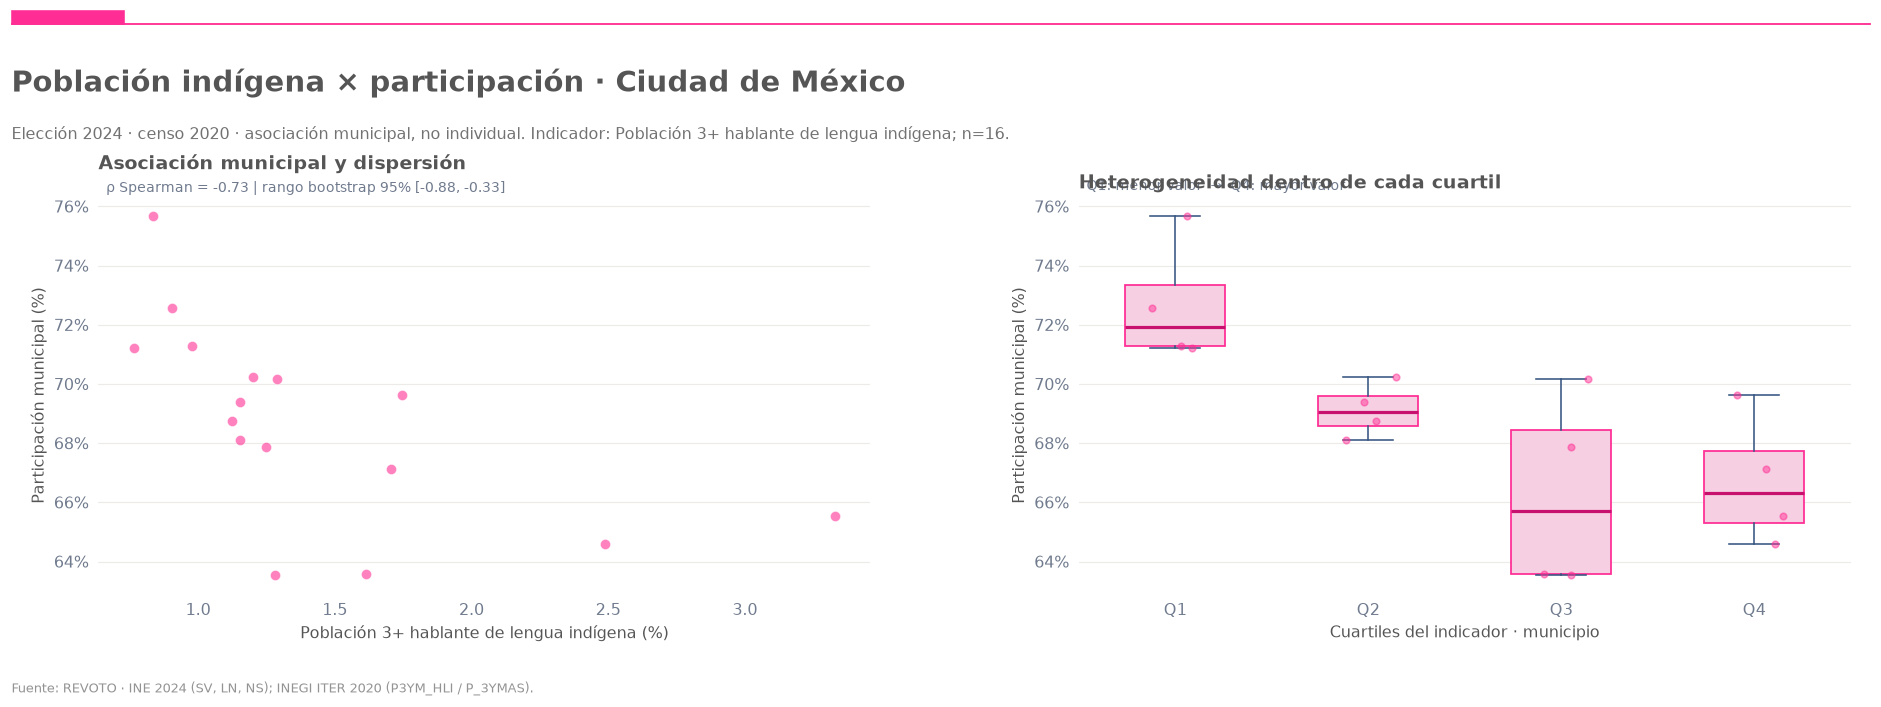

,dimension,indicador,cuartil,n,participacion_mediana_pct,participacion_ponderada_pct,indicador_mediana
0,indigena,habla_lengua_indigena,Q1 · menor,4,71.935034,72.909551,0.868777
1,indigena,habla_lengua_indigena,Q2,4,69.067411,69.037155,1.153339
2,indigena,habla_lengua_indigena,Q3,4,65.718647,65.964881,1.286000
3,indigena,habla_lengua_indigena,Q4 · mayor,4,66.326056,67.331580,2.118056


In [42]:
dibujar_dimension('indigena', 'Población indígena', 'habla_lengua_indigena', ('hogares_indigenas',))

### 5.6 · Población afromexicana

Proporción de personas censadas que se reconocen afromexicanas o afrodescendientes, no proporción de votantes con dicha identidad.

Dos lecturas complementarias, sujetas a cobertura suficiente: **relación bivariada** y **dispersión por cuartiles municipales**. El reporte indica fuente, denominador y `n`.

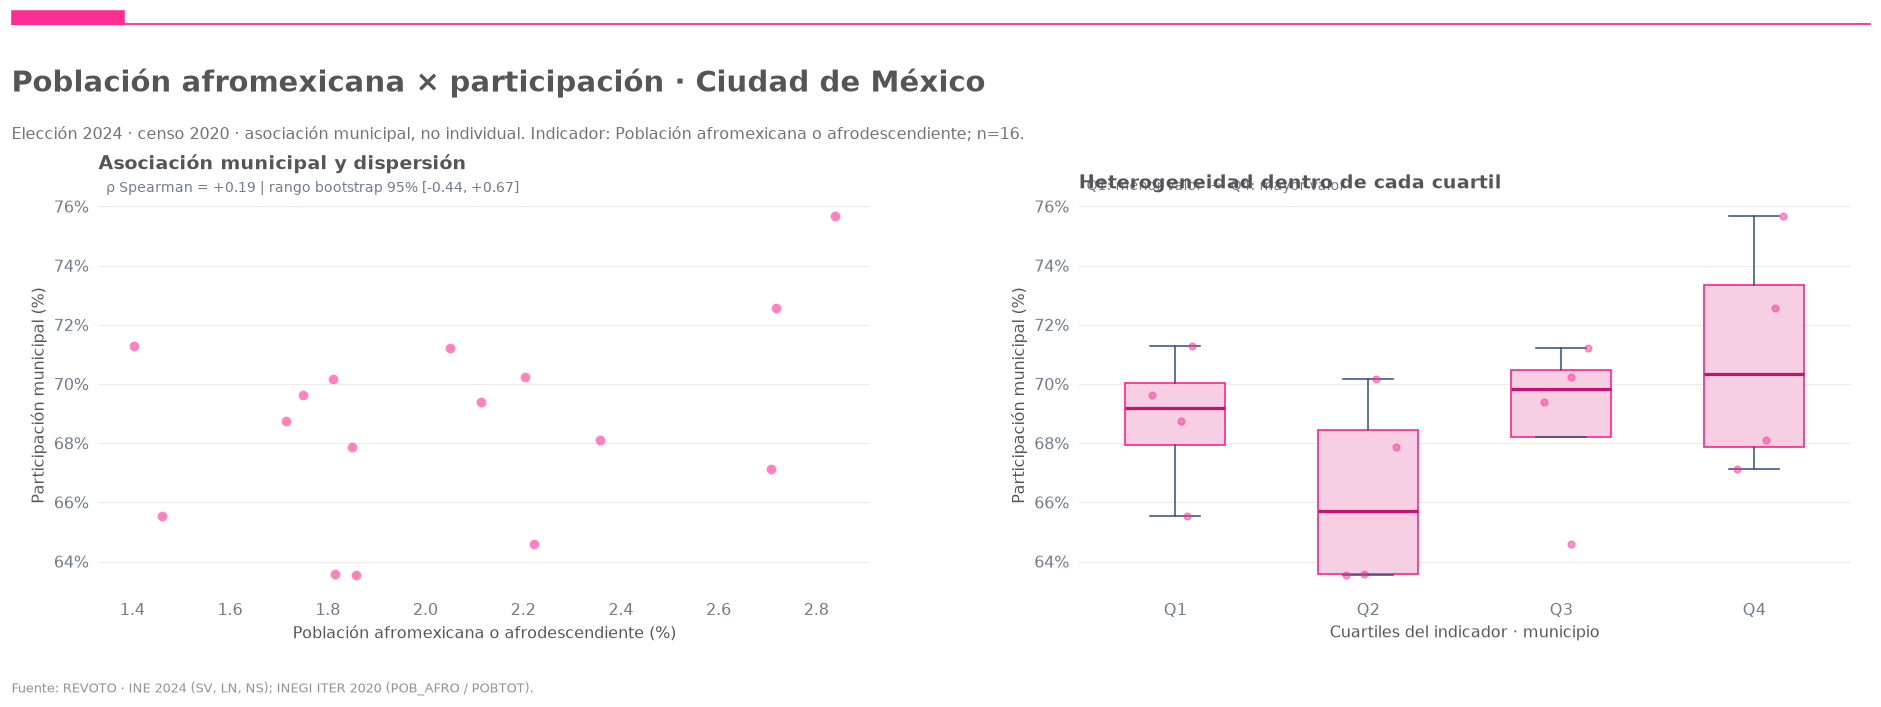

,dimension,indicador,cuartil,n,participacion_mediana_pct,participacion_ponderada_pct,indicador_mediana
0,afro,afromexicana,Q1 · menor,4,69.175686,69.221087,1.588149
1,afro,afromexicana,Q2,4,65.718647,65.964881,1.832045
2,afro,afromexicana,Q3,4,69.818334,68.838222,2.158879
3,afro,afromexicana,Q4 · mayor,4,70.348209,70.528309,2.712370


In [43]:
dibujar_dimension('afro', 'Población afromexicana', 'afromexicana', ())

## 6 · Panorama comparativo: las seis dimensiones

Comparación de ρ de Spearman **solo si hay suficiente cobertura**. No ordenar relaciones por magnitud absoluta como prueba de causalidad. Los indicadores pueden compartir denominadores y factores de contexto; ninguna asociación está ajustada por confusores.

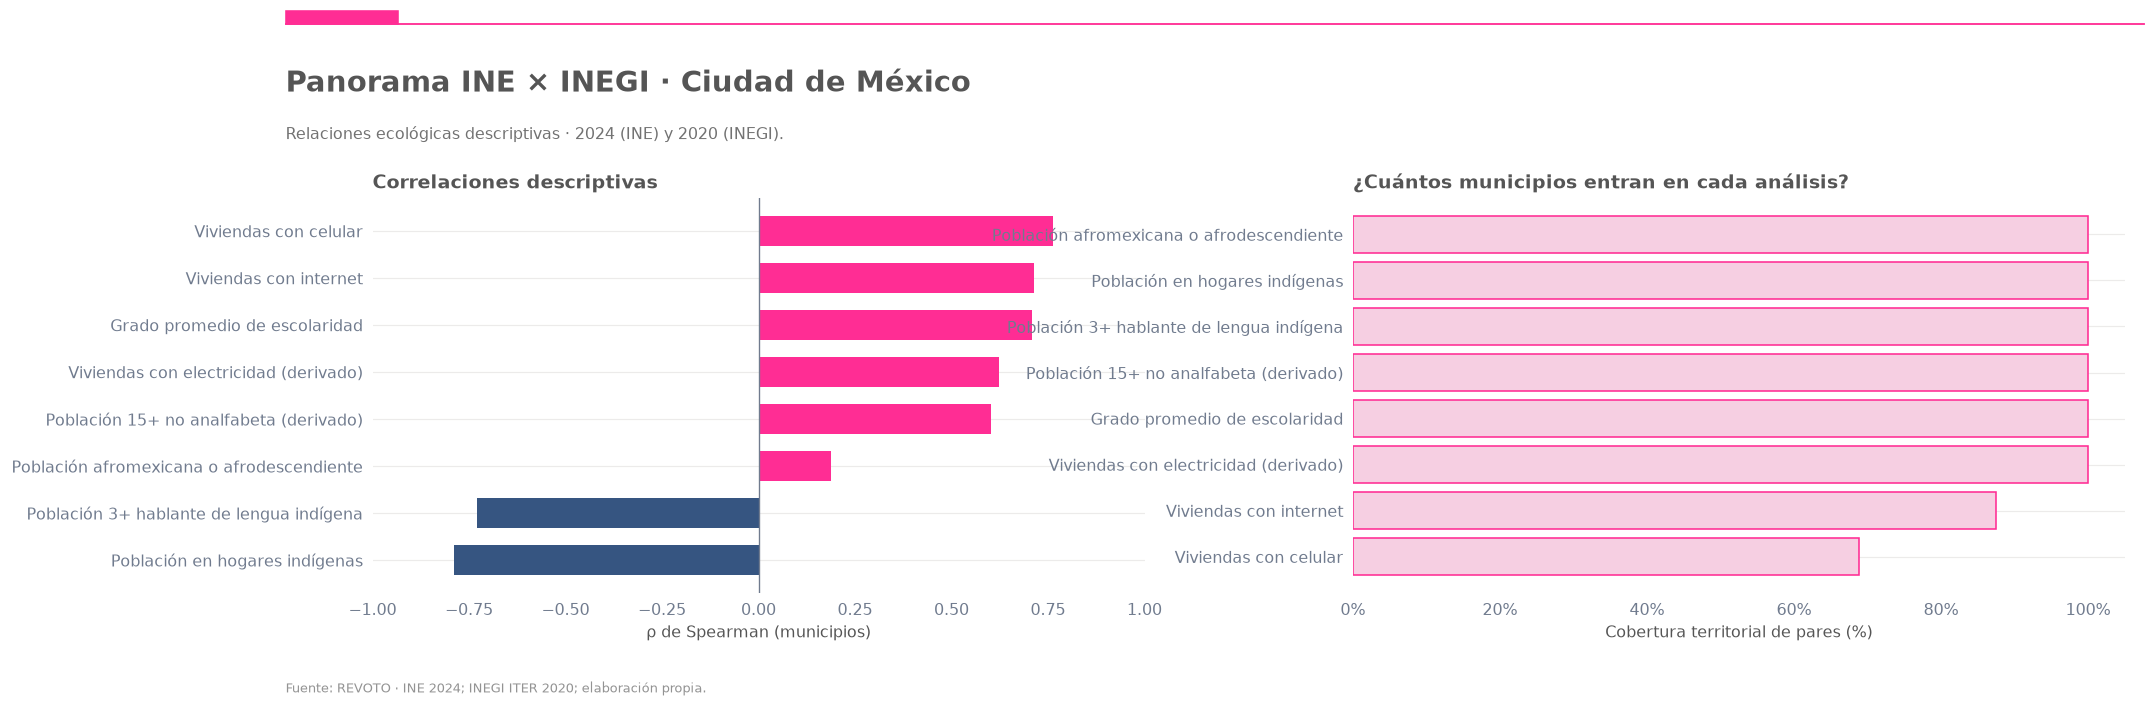

,indicador,dominio,descripcion,fuente,n,porcentaje_cobertura,rho_spearman,ci95_inf_boot,ci95_sup_boot
7,afromexicana,afro,Población que se reconoce afromexicana/afrodes...,POB_AFRO / POBTOT,16,100.0,0.188235,-0.442393,0.668962
2,celular_viviendas,celulares,Viviendas particulares habitadas que disponen ...,VPH_CEL / VIVPAR_HAB,11,68.8,0.763636,0.383048,0.990525
3,escolaridad,educacion,"Años promedio de escolaridad, población objeti...",GRAPROES,16,100.0,0.707874,0.261032,0.916853
4,sin_analfabetismo_15,educacion,Complemento de población de 15 años y más anal...,1 − P15YM_AN / P_15YMAS,16,100.0,0.602941,0.109262,0.852410
0,acceso_electricidad,electricidad,100 − porcentaje de viviendas sin electricidad,VPH_S_ELEC / VIVPAR_HAB,16,100.0,0.623529,0.176071,0.913533
5,habla_lengua_indigena,indigena,Porcentaje entre población de 3 años y más,P3YM_HLI / P_3YMAS,16,100.0,-0.729412,-0.880588,-0.333284
6,hogares_indigenas,indigena,Proporción de la población total en hogares in...,PHOG_IND / POBTOT,16,100.0,-0.788235,-0.934238,-0.449920
1,internet_viviendas,internet,Viviendas particulares habitadas con internet,VPH_INTER / VIVPAR_HAB,14,87.5,0.714286,0.207649,0.932134


In [44]:
tabla_orden=RESULTADOS.copy()
tabla_orden['etiqueta']=tabla_orden.indicador.map(lambda k:INDICADORES[k]['titulo'])
validas=tabla_orden.dropna(subset=['rho_spearman']).sort_values('rho_spearman')
fig,axs=pagina(f'Panorama INE × INEGI · {NOMBRE_ESTADO}',
    f'Relaciones ecológicas descriptivas · {ANIO_ELECTORAL} (INE) y {ANIO_CENSO} (INEGI).')
a,b=axs
if not validas.empty:
    pal=[AZUL if v<0 else ACENTO for v in validas.rho_spearman]
    a.barh(validas.etiqueta,validas.rho_spearman,color=pal,height=.65)
    a.axvline(0,color=GRIS2,lw=.85)
    a.set_xlim(-1,1);a.set_xlabel('ρ de Spearman (municipios)')
else:
    a.text(.5,.5,'Sin asociaciones calculables',transform=a.transAxes,ha='center',va='center')
a.set_title('Correlaciones descriptivas',loc='left',weight='bold')
cob=tabla_orden.sort_values('porcentaje_cobertura')
b.barh(cob.etiqueta,cob.porcentaje_cobertura,color=CLARO,edgecolor=ACENTO)
b.set_xlim(0,105); b.set_xlabel('Cobertura territorial de pares (%)')
b.set_title('¿Cuántos municipios entran en cada análisis?',loc='left',weight='bold')
marca_pct(b,'x')
cerrar(fig,'06_panorama')
mostrar(RESULTADOS.sort_values('dominio'),20)

## 7 · Comparación cruzada de dimensiones y condiciones del territorio

La pregunta adicional es si la asociación de un indicador cambia visualmente entre municipios con distintos niveles de escolaridad. Dividimos municipios por la mediana de `GRAPROES` y cruzamos con la mediana de internet (cuando ambos están disponibles). Son **cuatro grupos municipales**, no individuos; los cortes pueden ser inestables con muestras pequeñas.

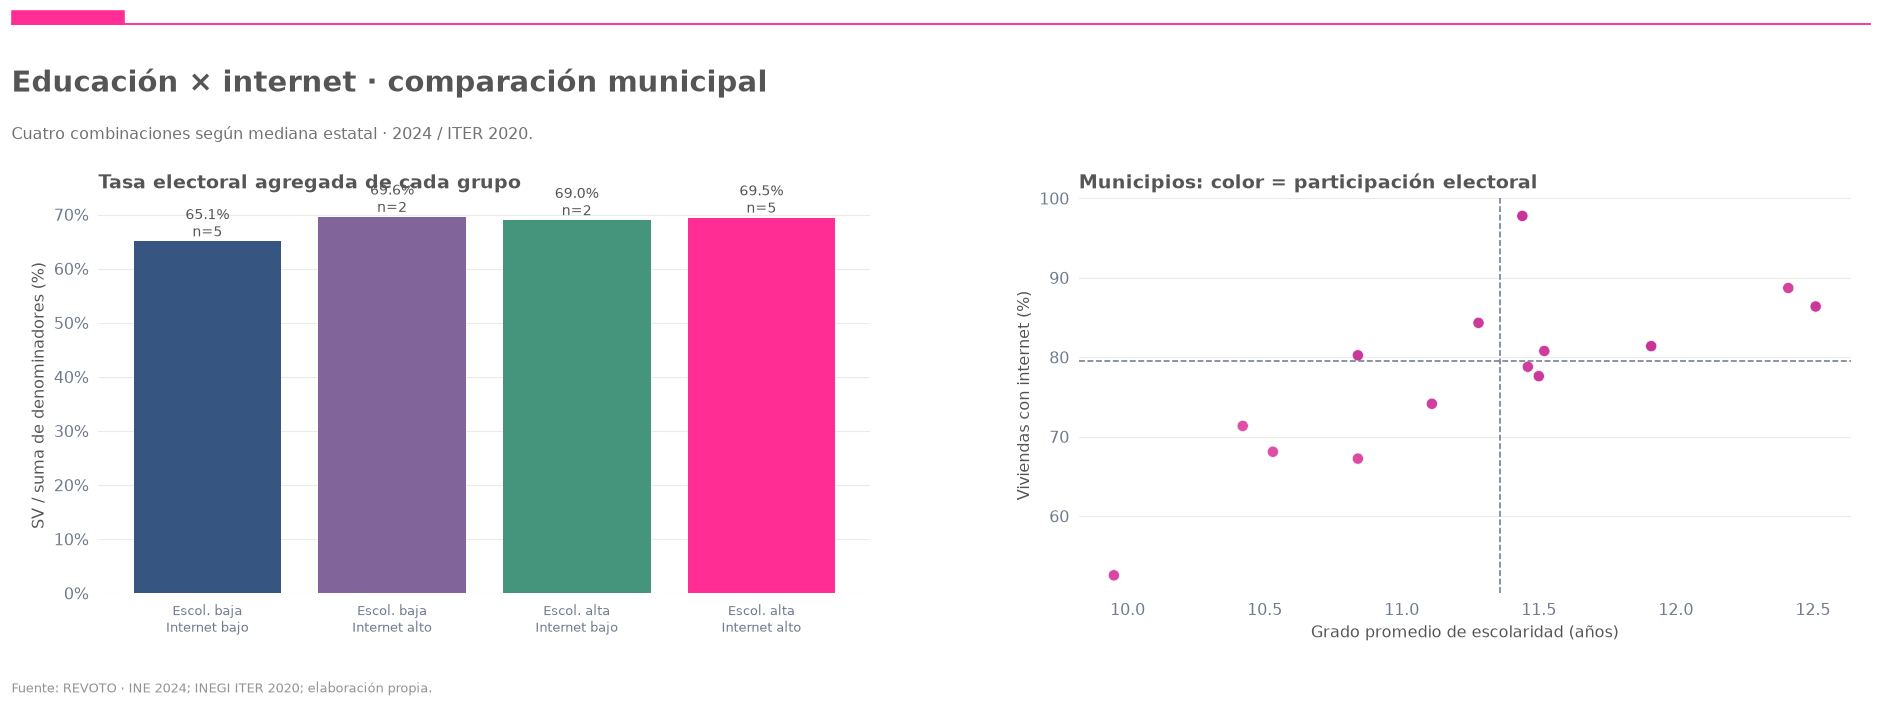

,educacion_alta,internet_alto,n,SV,denominador,mediana_tasa,tasa_ponderada_pct
0,False,False,5,2204454,3386879,0.645953,65.088065
1,False,True,2,580245,833519,0.698183,69.613890
2,True,False,2,678502,983304,0.688698,69.002262
3,True,True,5,1390559,2001687,0.701843,69.469353


In [45]:
CRUCE_EDUCACION_INTERNET=pd.DataFrame()
cr=base[['escolaridad','internet_viviendas','SV','LN','denominador','tasa']].dropna().copy()
cr=cr.loc[cr['denominador'].gt(0)&cr.tasa.between(0,1)].copy()
if len(cr)>=12 and cr.escolaridad.nunique()>2 and cr.internet_viviendas.nunique()>2:
    cr['educacion_alta']=cr.escolaridad.ge(cr.escolaridad.median())
    cr['internet_alto']=cr.internet_viviendas.ge(cr.internet_viviendas.median())
    CRUCE_EDUCACION_INTERNET=cr.groupby(['educacion_alta','internet_alto'],as_index=False).agg(
        n=('tasa','size'),SV=('SV','sum'),denominador=('denominador','sum'),
        mediana_tasa=('tasa','median'))
    CRUCE_EDUCACION_INTERNET['tasa_ponderada_pct']=100*safe_div(
        CRUCE_EDUCACION_INTERNET.SV,CRUCE_EDUCACION_INTERNET.denominador)
    fig,axs=pagina('Educación × internet · comparación municipal',
        f'Cuatro combinaciones según mediana estatal · {ANIO_ELECTORAL} / ITER {ANIO_CENSO}.')
    a,b=axs
    cols=[(False,False),(False,True),(True,False),(True,True)]
    etiqueta=lambda e,i:('Escol. alta' if e else 'Escol. baja')+'\n'+('Internet alto' if i else 'Internet bajo')
    grupos=[CRUCE_EDUCACION_INTERNET.loc[(CRUCE_EDUCACION_INTERNET.educacion_alta==e)&
             (CRUCE_EDUCACION_INTERNET.internet_alto==i)] for e,i in cols]
    vals=[float(g.iloc[0].tasa_ponderada_pct) if len(g)>=1 else np.nan for g in grupos]
    ns=[int(g.iloc[0].n) if len(g) else 0 for g in grupos]
    a.bar(range(4),np.nan_to_num(vals,nan=0),color=[AZUL,MORADO,VERDE,ACENTO])
    a.set_xticks(range(4),[etiqueta(*z) for z in cols],fontsize=8)
    a.set_title('Tasa electoral agregada de cada grupo',loc='left',weight='bold')
    a.set_ylabel('SV / suma de denominadores (%)');marca_pct(a)
    for i,(v,n) in enumerate(zip(vals,ns)):
        if np.isfinite(v): a.text(i,v,f'{v:.1f}%\nn={n}',ha='center',va='bottom',fontsize=9)
    b.scatter(cr.escolaridad,cr.internet_viviendas,c=cr.tasa*100,
              cmap='RdPu',vmin=0,vmax=100,s=50,alpha=.85,edgecolors='white',linewidths=.5)
    b.axvline(cr.escolaridad.median(),ls='--',color=GRIS2,lw=1)
    b.axhline(cr.internet_viviendas.median(),ls='--',color=GRIS2,lw=1)
    b.set_xlabel('Grado promedio de escolaridad (años)')
    b.set_ylabel('Viviendas con internet (%)')
    b.set_title('Municipios: color = participación electoral',loc='left',weight='bold')
    cerrar(fig,'07_cruce_educacion_internet')
    mostrar(CRUCE_EDUCACION_INTERNET,8)
else:
    nota('Cruce escolaridad × internet omitido por insuficiencia de indicadores o de municipios.')

## 8 · Sensibilidad: municipios grandes, denominadores y observaciones influyentes

Recalculamos correlaciones retirando el municipio con la mayor `LN` y filtrando por `LN ≥ UMBRAL_LN_EXPLORATORIO`. Los coeficientes se muestran junto con el número de pares. Esto no reemplaza controles estadísticos multivariados; permite detectar conclusiones frágiles frente a observaciones influyentes.

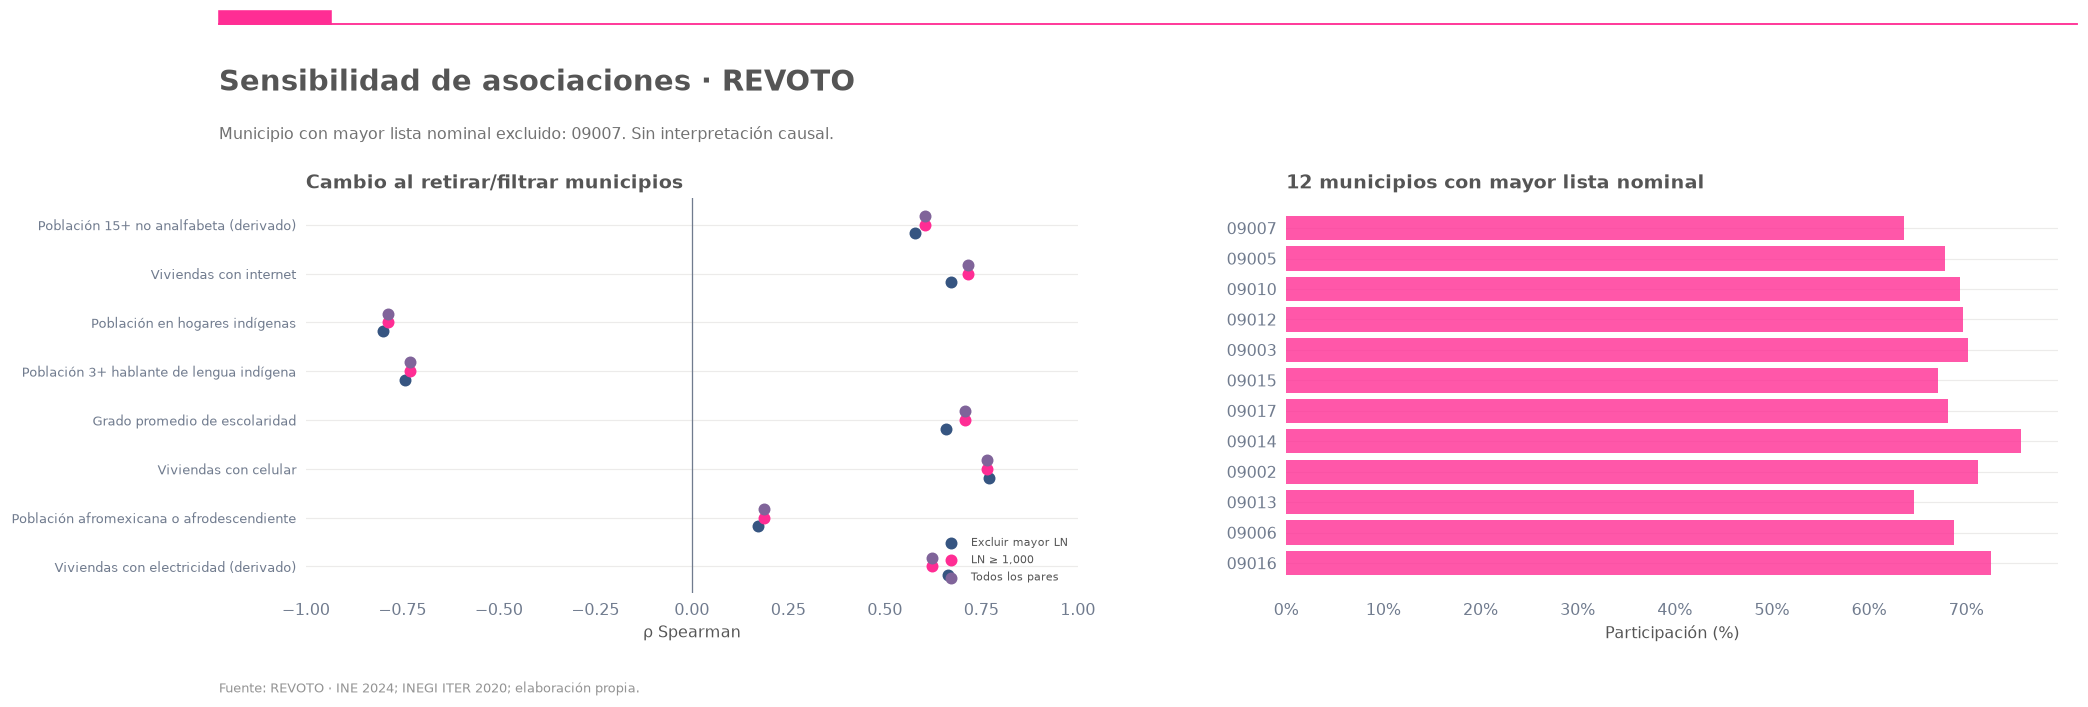

,indicador,escenario,n,rho_spearman
0,acceso_electricidad,Todos los pares,16,0.623529
1,acceso_electricidad,Excluir mayor LN,15,0.664286
2,acceso_electricidad,"LN ≥ 1,000",16,0.623529
3,internet_viviendas,Todos los pares,14,0.714286
4,internet_viviendas,Excluir mayor LN,13,0.670330
5,internet_viviendas,"LN ≥ 1,000",14,0.714286
6,celular_viviendas,Todos los pares,11,0.763636
7,celular_viviendas,Excluir mayor LN,10,0.769697
8,celular_viviendas,"LN ≥ 1,000",11,0.763636
9,escolaridad,Todos los pares,16,0.707874


In [46]:
fila_mayor=base.loc[base.LN.idxmax()]
MUN_MAYOR=str(fila_mayor.cvegeo_municipal)
SENSIBILIDAD=[]
for nombre in INDICADORES:
    d=dataset_indicador(nombre)
    for etiqueta,sub in [
        ('Todos los pares',d),
        ('Excluir mayor LN',d.loc[d.cvegeo_municipal.ne(MUN_MAYOR)]),
        (f'LN ≥ {UMBRAL_LN_EXPLORATORIO:,}',d.loc[d.LN.ge(UMBRAL_LN_EXPLORATORIO)])]:
        rho,_,_=correlacion(sub,nombre)
        SENSIBILIDAD.append({'indicador':nombre,'escenario':etiqueta,
                             'n':len(sub),'rho_spearman':rho})
SENSIBILIDAD=pd.DataFrame(SENSIBILIDAD)
sm=SENSIBILIDAD.pivot(index='indicador',columns='escenario',values='rho_spearman')
fig,axs=pagina('Sensibilidad de asociaciones · REVOTO',
    f'Municipio con mayor lista nominal excluido: {MUN_MAYOR}. Sin interpretación causal.')
a,b=axs
orden=list(sm.index)
if sm.notna().any().any():
    y=np.arange(len(orden))
    colores=[AZUL,ACENTO,MORADO]
    for k,(nombre,serie) in enumerate(sm.items()):
        a.scatter(serie.reindex(orden),y+(k-1)*.18,label=nombre,color=colores[k%3],s=42)
    a.set_yticks(y,[INDICADORES[k]['titulo'] for k in orden],fontsize=8)
    a.axvline(0,color=GRIS2,lw=.8)
    a.set_xlim(-1,1);a.set_xlabel('ρ Spearman')
    a.legend(frameon=False,fontsize=7,loc='lower right')
a.set_title('Cambio al retirar/filtrar municipios',loc='left',weight='bold')
desbalance=electoral.sort_values('LN',ascending=False).head(12)
b.barh(desbalance.cvegeo_ine.astype(str),desbalance.tasa*100,color=ACENTO,alpha=.8)
b.invert_yaxis();b.set_xlabel('Participación (%)');marca_pct(b,'x')
b.set_title('12 municipios con mayor lista nominal',loc='left',weight='bold')
cerrar(fig,'08_sensibilidad')
mostrar(SENSIBILIDAD,30)

## 9 · Tabulación de municipios y contraste descriptivo

Permite localizar municipios representativos **con sus nombres INEGI observados** y distinguir tasa, lista nominal, tamaño de población y condiciones sociales. Los rankings no implican características de votantes individuales y pueden ser sensibles a municipios pequeños.

In [47]:
columnas_perfil=['cvegeo_municipal','NOM_MUN','LN','SV','NV','NS','tasa',
    'POBTOT','acceso_electricidad','escolaridad','internet_viviendas',
    'celular_viviendas','habla_lengua_indigena','hogares_indigenas','afromexicana']
PERFIL=base[columnas_perfil].copy().sort_values('tasa',ascending=False)
PERFIL['participacion_pct']=100*PERFIL['tasa']
cols_vista=['NOM_MUN','cvegeo_municipal','LN','SV','NV','participacion_pct',
    'acceso_electricidad','escolaridad','internet_viviendas','celular_viviendas',
    'habla_lengua_indigena','hogares_indigenas','afromexicana']
print('Diez municipios con mayor tasa observada:')
mostrar(PERFIL[cols_vista],10)
print('Diez municipios con menor tasa observada:')
mostrar(PERFIL[cols_vista].tail(10).sort_values('participacion_pct'),10)

Diez municipios con mayor tasa observada:


,NOM_MUN,cvegeo_municipal,LN,SV,NV,participacion_pct,acceso_electricidad,escolaridad,internet_viviendas,celular_viviendas,habla_lengua_indigena,hogares_indigenas,afromexicana
12,Benito Juárez,09014,384037,290639,89728,75.679948,99.982004,14.55,NaN,NaN,0.833341,1.290789,2.838861
14,Miguel Hidalgo,09016,329164,238889,88953,72.574461,99.963464,13.11,NaN,NaN,0.904213,1.476343,2.717205
2,Cuajimalpa de Morelos,09004,188128,134127,50416,71.295607,99.934649,11.44,97.792816,NaN,0.976425,1.847615,1.402479
0,Azcapotzalco,09002,384017,273485,106454,71.216899,99.970789,11.91,81.404412,95.288646,0.763708,1.679990,2.050879
6,La Magdalena Contreras,09008,212549,149285,61675,70.235569,99.879598,10.84,80.246190,98.675581,1.202373,2.744506,2.204570
1,Coyoacán,09003,571993,401449,148552,70.184251,99.966628,12.51,86.389076,98.081373,1.289014,2.498019,1.809757
10,Tlalpan,09012,578734,402901,174006,69.617648,99.859939,11.50,77.624994,96.280204,1.746271,4.111566,1.749466
8,Álvaro Obregón,09010,620970,430960,180535,69.401098,99.963105,11.28,84.327588,NaN,1.152081,2.429206,2.113189
4,Iztacalco,09006,364028,250210,110369,68.733724,99.953854,11.52,80.789266,96.468093,1.122675,2.485823,1.715119
15,Venustiano Carranza,09017,404570,275601,120385,68.121957,99.959054,11.46,78.808387,95.987268,1.154597,2.286434,2.358104


Diez municipios con menor tasa observada:


,NOM_MUN,cvegeo_municipal,LN,SV,NV,participacion_pct,acceso_electricidad,escolaridad,internet_viviendas,celular_viviendas,habla_lengua_indigena,hogares_indigenas,afromexicana
9,Tláhuac,09011,318687,202477,113564,63.534754,99.770128,10.53,68.106441,91.209997,1.282985,3.360582,1.857955
5,Iztapalapa,09007,1524929,969535,501425,63.579026,99.938680,10.42,71.356477,93.045920,1.615815,3.979110,1.814942
11,Xochimilco,09013,367672,237499,124979,64.595346,99.785782,10.84,67.243673,92.168092,2.489842,5.845157,2.223087
7,Milpa Alta,09009,119674,78416,40536,65.524675,99.599129,9.95,52.559201,89.850802,3.330678,8.515571,1.461178
13,Cuauhtémoc,09015,493521,331288,155053,67.127437,99.953863,12.41,88.719968,NaN,1.705650,3.381854,2.707535
3,Gustavo A. Madero,09005,1055917,716527,317350,67.858269,99.951830,11.11,74.145281,92.365033,1.247610,2.815441,1.849148
15,Venustiano Carranza,09017,404570,275601,120385,68.121957,99.959054,11.46,78.808387,95.987268,1.154597,2.286434,2.358104
4,Iztacalco,09006,364028,250210,110369,68.733724,99.953854,11.52,80.789266,96.468093,1.122675,2.485823,1.715119
8,Álvaro Obregón,09010,620970,430960,180535,69.401098,99.963105,11.28,84.327588,NaN,1.152081,2.429206,2.113189
10,Tlalpan,09012,578734,402901,174006,69.617648,99.859939,11.50,77.624994,96.280204,1.746271,4.111566,1.749466


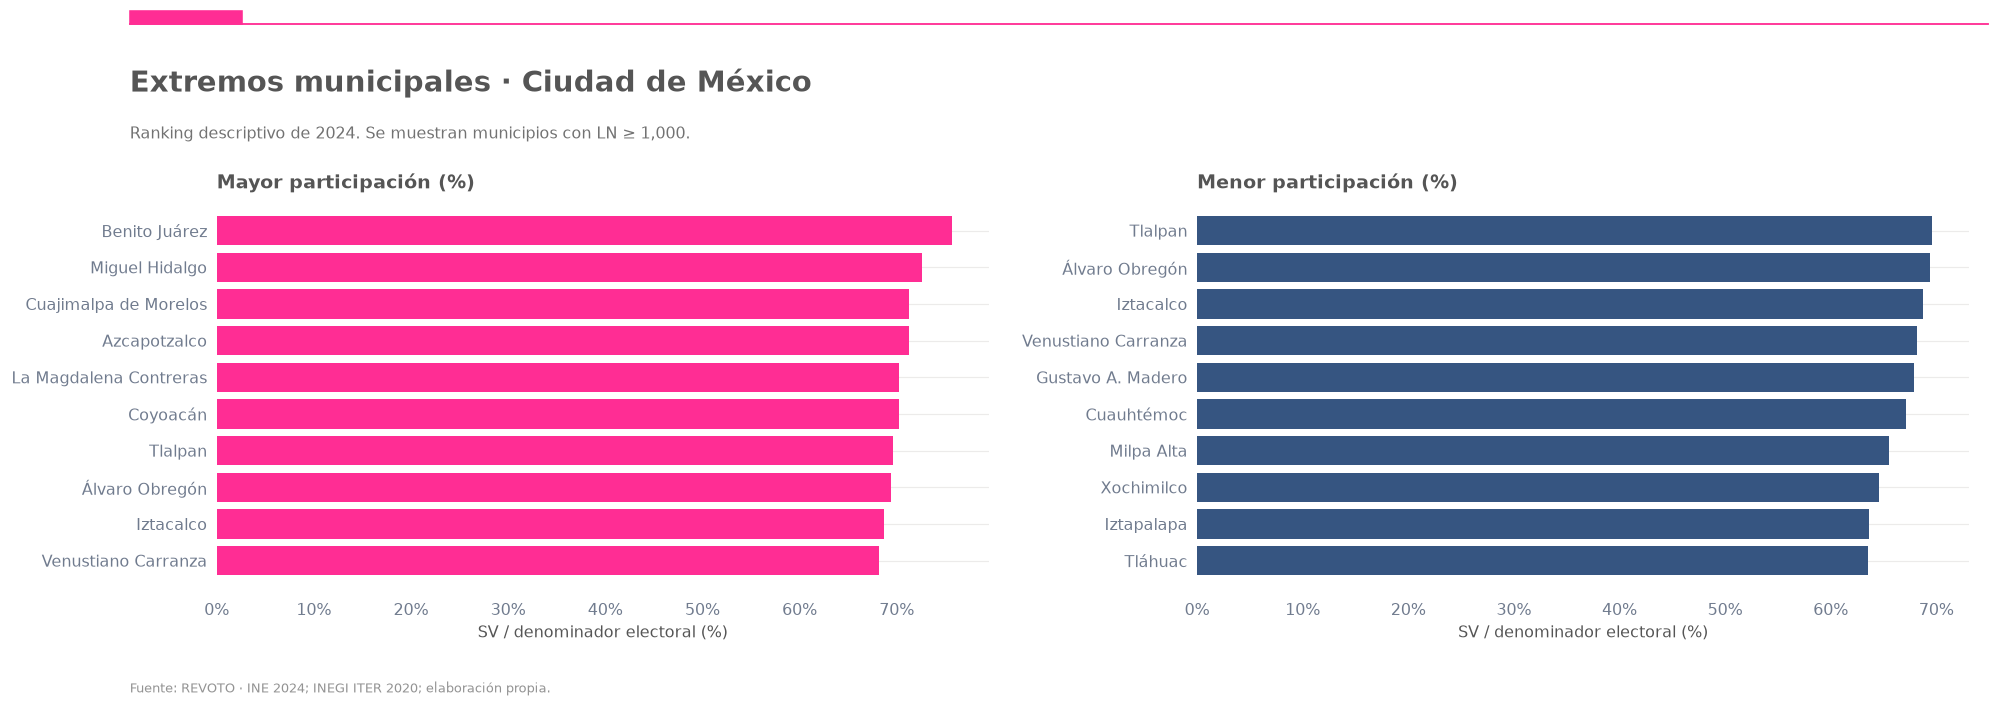

In [48]:
fig,axs=pagina(f'Extremos municipales · {NOMBRE_ESTADO}',
     f'Ranking descriptivo de {ANIO_ELECTORAL}. Se muestran municipios con LN ≥ {UMBRAL_LN_EXPLORATORIO:,}.')
a,b=axs
viz=PERFIL.loc[PERFIL.LN.ge(UMBRAL_LN_EXPLORATORIO)].copy()
if len(viz)>=4:
    mas=viz.head(10).sort_values('tasa')
    menos=viz.tail(10).sort_values('tasa')
    a.barh(mas.NOM_MUN.fillna(mas.cvegeo_municipal),mas.tasa*100,color=ACENTO)
    b.barh(menos.NOM_MUN.fillna(menos.cvegeo_municipal),menos.tasa*100,color=AZUL)
    a.set_title('Mayor participación (%)',loc='left',weight='bold')
    b.set_title('Menor participación (%)',loc='left',weight='bold')
    for ax in axs: ax.set_xlabel('SV / denominador electoral (%)');marca_pct(ax,'x')
else:
    for ax in axs: ax.set_axis_off()
    nota('Ranking no disponible tras filtro exploratorio de LN.')
cerrar(fig,'09_extremos')

## 10 · Hallazgos, limitaciones y decisiones para el producto

**Lectura editorial guiada por evidencia:** el texto siguiente se genera a partir de las métricas realmente computadas. La existencia de una correlación no prueba un mecanismo, una explicación de abstención ni el sentido del voto. Las diferencias entre censos de 2010/2020 y elecciones de otros años deben documentarse, en particular si hay cambios territoriales.

In [49]:
disponibles=RESULTADOS.dropna(subset=['rho_spearman']).copy()
num_join=int(base.match_iter.eq('both').sum())
texto=[f'## Ficha ejecutiva · {NOMBRE_ESTADO} ({ANIO_ELECTORAL})',
 f'- Se observaron **{len(electoral)} municipios electorales**; '
 f'**{num_join}** se emparejaron con total municipal ITER {ANIO_CENSO}.',
 f'- Tasa estatal recalculada: **{100*electoral.SV.sum()/electoral.denominador.sum():.1f}%** '
 f'con métrica **{METRICA_PARTICIPACION}** (suma de SV / suma de denominadores).',
 f'- No votantes NV registrados: **{electoral.NV.sum():,.0f}**; '
 f'**no** restados directamente a la tasa.',
 f'- Indicadores con correlación descriptiva calculable: **{len(disponibles)}/{len(INDICADORES)}**.']
if not disponibles.empty:
    mayor=disponibles.loc[disponibles.rho_spearman.abs().idxmax()]
    tendencia='positiva' if mayor.rho_spearman>0 else 'negativa'
    texto.append(f'- Mayor |ρ| observado: **{INDICADORES[mayor.indicador]["titulo"]}** '
        f'con ρ={mayor.rho_spearman:+.2f}, n={int(mayor.n)}; '
        f'asociación ecológica **{tendencia}**, no causal.')
else:
    texto.append('- No hay datos suficientes para formular asociaciones entre dimensiones.')
texto.append('- Los indicadores de vivienda son proporciones de **viviendas**, no de personas; los de identidad refieren a población **censada**, no a votantes.')
texto.append('- Prioridades: corroborar definición de NS/NV en el diccionario INE, cobertura/mappings, denominadores ITER, valores suprimidos y estabilidad ante LN.')
texto.append('- Uso para REVOTO: formular **preguntas exploratorias**, no etiquetas ni predicciones sobre individuos o comunidades.')
INFORME='\n'.join(texto)
display(Markdown(INFORME))

## Ficha ejecutiva · Ciudad de México (2024)
- Se observaron **16 municipios electorales**; **16** se emparejaron con total municipal ITER 2020.
- Tasa estatal recalculada: **68.0%** con métrica **LN** (suma de SV / suma de denominadores).
- No votantes NV registrados: **2,383,980**; **no** restados directamente a la tasa.
- Indicadores con correlación descriptiva calculable: **8/8**.
- Mayor |ρ| observado: **Población en hogares indígenas** con ρ=-0.79, n=16; asociación ecológica **negativa**, no causal.
- Los indicadores de vivienda son proporciones de **viviendas**, no de personas; los de identidad refieren a población **censada**, no a votantes.
- Prioridades: corroborar definición de NS/NV en el diccionario INE, cobertura/mappings, denominadores ITER, valores suprimidos y estabilidad ante LN.
- Uso para REVOTO: formular **preguntas exploratorias**, no etiquetas ni predicciones sobre individuos o comunidades.

## 11 · Exportaciones y reproducibilidad

Todas las salidas se guardan únicamente bajo `apps/pipeline/reportes/eda_ine_inegi/edo=XX/anio=AAAA/`. Se incluyen el dataset municipal integrado (solo en ubicación local), cobertura, definiciones, cuartiles, sensibilidades y metadatos del análisis. **No se publica automáticamente información territorial sensible ni se sube a GitHub.**

In [50]:
def guardar(df,nombre):
    if df is None or not isinstance(df,pd.DataFrame): return
    df.to_csv(SALIDA/nombre,index=False,encoding='utf-8-sig')

guardar(base,'01_dataset_municipal_ine_inegi.csv')
guardar(auditoria_join,'02_auditoria_union.csv')
guardar(control_ine,'03_auditoria_ine.csv')
guardar(CONTRATO,'04_definiciones_disponibilidad.csv')
guardar(RESULTADOS,'05_correlaciones.csv')
guardar(SENSIBILIDAD,'06_sensibilidad.csv')
guardar(PERFIL,'07_perfil_municipal.csv')
guardar(CRUCE_EDUCACION_INTERNET,'08_educacion_internet.csv')
guardar(pd.concat(CUARTILES.values(),ignore_index=True) if CUARTILES else pd.DataFrame(),
       '09_cuartiles.csv')
(SALIDA/'10_resumen_ejecutivo.md').write_text(INFORME,encoding='utf-8')
meta={'estado':NOMBRE_ESTADO,'edo':EDO,'anio_eleccion':ANIO_ELECTORAL,
    'censo_ref':ANIO_CENSO,'metrica_participacion':METRICA_PARTICIPACION,
    'input_mart':str(RUTA_MART),'input_iter':str(RUTA_ITER),
    'input_full_context':str(RUTA_FULL) if RUTA_FULL.exists() else None,
    'mapping_csv':str(RUTA_MAPPING) if RUTA_MAPPING.exists() else None,
    'raw_iter_csv':str(raw_csv[0]) if len(raw_csv)==1 and USAR_CSV_ITER_PARA_DENOMINADORES else None,
    'denominador_viviendas':DEN_VIV,'denominador_lengua_indigena':DEN_IND,
    'conteo_municipios':len(electoral),'municipios_unidos':int(base.match_iter.eq('both').sum()),
    'join_directo':PERMITIR_JOIN_CVEGEO_DIRECTO,
    'fecha_utc':datetime.now(timezone.utc).isoformat(),
    'fuente_repositorio':'https://github.com/AzizaCorp/ReVoto/tree/feat/US-06-dataset-pipeline',
    'advertencia':'EDA descriptivo municipal; sin inferencia individual ni causalidad.'}
(SALIDA/'11_procedencia.json').write_text(json.dumps(meta,indent=2,ensure_ascii=False,default=str),encoding='utf-8')
print('Exportaciones en:',SALIDA)
print('Figuras:',len(FIGURAS_CREADAS))

Exportaciones en: D:\Almacenamiento\CodingLab\projects\personal\ReVoto\apps\pipeline\reportes\eda_ine_inegi\edo=09\anio=2024
Figuras: 12
